# Is plan noise the cheapest route to diverse code?

**Pricing "creativity knobs" for Qwen3-8B by the *correct algorithmic diversity* they buy: a runnable demo of the experiment's analysis stage.**

Ask Qwen3-8B to find a path through a grid and it writes **BFS** almost every time. Ask for the k-th smallest element and it sorts the whole list. This experiment (iteration 4, Step 1 / Claim 1) asks which *knob* buys **correct algorithmic diversity** most cheaply:

| knob class | what it does |
|---|---|
| **PN, plan noise** (the candidate) | One fresh isotropic unit direction per sample is added to the residual stream at the task-spec positions of decoder blocks 12–23, during the prompt prefill only. The size alpha ∈ {0.5, 1, 2, 4} is in *ban units*: alpha = 1 is as large as the shift a real "Do not use X" instruction causes. |
| TEMP | temperature 1.3 or 1.6 (untruncated) |
| TOPK10 | top-k 10 |
| NONCE | the nonce ban "Do not use the Zorblax method …" |
| NOVELTY | "Write a novel algorithm for this task, one you have not seen before." |
| SEMSEED | a short semantic-seed story (path tasks only) |
| VETO_1SHOT / VETO_PERSIST / VETO_ITER | iteration-3 signature vetoes (reused rows): ban the algorithm the model just used |

Each arm samples **N = 50 programs per task** (5 prompt templates × 10 slots). Every arm reuses the same random numbers for each slot (*common random numbers*, CRN). Each program is run against tests (pass / fail) and labelled with its algorithm (`bfs`, `dfs`, `quickselect`, …). Each knob is scored as follows:

- **Statistic:** correct-only **Hill-1 rarefied at depth 25**, the effective number of distinct *correct* algorithms among 25 programs (1.0 = always the same idea).
- **Randomisation hull:** a knob is priced on the mixtures of its reference arm and its settings.
- **H5:** the best Hill reachable at a pass-rate cost of at most 5 points.
- **P15 / P20:** the cheapest cost at which Hill reaches 1.5 / 2.

**Full-run result:** the pre-registered rule C1 ("PN is the cheapest knob") is **PARTIAL**.

- PN wins on T03 and T10, ties on T05 and T1, and loses on T06 (to the iterated veto) and T2 (to the semantic seed).
- Temperature, top-k and the nonce ban buy no correct algorithmic diversity (H5 ≤ 1.09). Temperature changes the *code* but almost never the *algorithm*.

### What this notebook runs
`method.py` is an orchestrator over 11 stages; each stage calls a script in `src/`. Not everything can run here:

- **GPU stage:** Qwen3-8B FP8 on a ≥ 16 GB FP8-capable GPU, 10,100 programs, 2.5 GPU-hours.
- **Labeller:** executes the generated code in a sandbox.
- **LLM audits:** call OpenRouter.

The notebook therefore runs the **CPU analysis** on the artifact's own labelled programs:

| `method.py` stage | in this notebook |
|---|---|
| `prompts`, `inputs`, `screen`, `commit` | not run: prompt rendering, input hashes and pre-registration; example prompts are shown |
| `gpu`, `label`, `label_ec` | not run: their output (labelled programs) is the input data. The PN direction of every sample is re-derived from its recorded seed. |
| `audit`, `validity` (OpenRouter) | not run: their result, the 'other'-label map, is shipped with the data |
| **`analyze`** (`src/analysis/run_all.py`, `descriptive.py`) | **run**: knob rows, hull prices, bootstraps, the C1 rule with sensitivities s1 and s3–s8, descriptive analyses |
| **`report`** (`src/figures.py`) | **run**: figures 1, 2, 3, 4 and 6 inline, plus a plot of the realised displacement |

**Data.** `mini_demo_data.json` holds 99 (task, arm) cells of the 6 decisive tasks, 5,020 labelled programs in all. Generated code is included for T1, the grid path-search task.

- These are all the arms the C1 rule prices, plus PN at alpha 8.
- Left out: the sensitivity-only arms (min-p, verbalized sampling), PLAIN, the held-out task R2 and the 8 non-movable tasks.
- **Point estimates reproduce the full run exactly.** Bootstrap intervals use fewer replicates than the full run's 2,000 (see the config cell).

The code below is the original code, split into cells. Changes are limited to data access (in-memory instead of files), config variables instead of hard-coded sizes, and running the bootstrap jobs sequentially.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original analysis scripts log through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# Original imports of src/cfg.py, src/sampling_v4.py, src/figures.py and src/analysis/{stats_step0, hull, core,
# run_all, descriptive, metrics_exp6}.py, merged (the torch-, argparse- and file-only ones are not needed here).
import ast
import builtins
import hashlib
import itertools
import json
import math
import sys
import time
import zlib
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Callable, Iterable, Sequence

import numpy as np
from loguru import logger
from scipy.stats import norm

# Added for the notebook: inline figures (src/figures.py used matplotlib.use("Agg") and saved PDF/PNG files)
import matplotlib
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-4/experiment-19/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            d = json.loads(response.read().decode())
        # Added: an older demo file with another layout was once published at this URL; accept only this layout.
        if isinstance(d, dict) and d.get("datasets") and d["datasets"][0].get("dataset") == "e6_cells":
            return d
        print("GitHub data has an older layout, using local mini_demo_data.json")
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta, cells = data["metadata"], data["datasets"][0]["examples"]  # one dataset: one example per (task, arm) cell
print(f"{len(cells)} (task, arm) cells, {sum(c['n'] for c in cells)} labelled programs; model: {meta['model']}")
print("example cell:", cells[0]["input"], "->", cells[0]["output"])

GitHub data has an older layout, using local mini_demo_data.json
99 (task, arm) cells, 5020 labelled programs; model: Qwen/Qwen3-8B@b968826d9c46dd6066d109eabc6255188de91218 (fp8 w8a8 dynamic)
example cell: T03 | TWIN | this_run | engine hf_fp8 | prompt twin | T=1.0 top_k=0 min_p=0.0 alpha=None -> {"full_sort": 50}


## Configuration

All tunable parameters live in the next cell. The values are the demo scale; the full run's values are in the comments.

- **Point estimates** (knob rows, H5 / P15 / P20, the C1 counts and D̄) do not depend on the bootstrap sizes. At `N_SUB_POINT = 1000` they reproduce the full run exactly.
- **Bootstrap intervals** and the bootstrap probabilities P(H5_PN > H5_best) are Monte-Carlo estimates; their precision grows with `N_BOOT` and `N_BOOT_SENS`.
- **Cost:** one bootstrap replicate takes about 0.25 s for all 6 tasks on one CPU core. The full run used 2,000 primary and 1,000 sensitivity replicates on 6 processes.

In [5]:
# ---- bootstrap sizes (the expensive part: runtime grows linearly with them) ----
N_BOOT = 300             # primary bootstrap replicates per task (full run: 2000, `run_all.py --boot`)
N_BOOT_SENS = 50         # replicates of the s1/s3/s4/s5/s6/s8 sensitivity bootstraps (full run: 1000, `--boot-sens`)
N_BOOT_C1 = 2000         # task-bootstrap draws for the 95% CI of D_bar inside c1_decide (full run: 2000)
KNOB_ROWS_N_BOOT = 2000  # replicates of each knob row's 90% Step-0 Hill interval (full run: 2000)
WORKERS = 6              # bootstrap job chunks (their seeds depend on it); the notebook runs them one after another
                         # (full run: 6 worker processes)
# ---- Monte-Carlo precision of the hull statistic (rows of the fixed uniform matrix U) ----
N_SUB_POINT = 1000       # point-estimate hull (full run: 1000)
N_SUB_BOOT = 200         # inside bootstrap replicates (full run: 200)
N_SUB_TRIANGLE = 300     # 3-vertex-face check of the point prices (full run: 300)
N_SUB_FIG = 300          # figure-1 frontier (full run: 300)
# ---- descriptive analyses ----
IDEAS_TASKS = ["T1"]     # tasks of the ideas-vs-phrasings analysis; code ships for T1 only (full run: all 15 tasks)
IDEAS_N_SUB = 200        # subsamples per phrasing-cluster count (full run: 200)

## 1. Design constants (`src/cfg.py`)

The next cell copies the constants the analysis needs from `src/cfg.py`:

- the 6 decisive tasks (E6) and each task's **default** algorithm, i.e. what the model writes unprompted;
- the five prompt templates W1–W5, each with a ban form and a neutral *twin* form, in which neutral nouns replace the banned algorithm;
- the PN blocks and alphas, the arm definitions and the seeds.

Conventions stated in `cfg.py`:

- **Block numbering:** BLOCK l is decoder block l, counted from 0.
- **Spec positions:** SPEC positions S run from the first token of `Task:` to the last user token.
- **CRN slot:** a CRN slot is (task, template w, k). Its uniform stream is shared by every arm, so two arms differ at a slot only because of the knob.
- **PN direction:** PN direction of a row: `seed_k = stable_seed(task, arm, w, k)`; `u = x / ||x||`, `x ~ N(0, I_4096)`. One fresh direction per sample, shared across blocks 12–23 and the spec positions.

`cfg.N_BOOT = 2000` and the file paths are replaced by the config cell. Logging keeps the original stdout format, without the file sink.

In [6]:
# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
N_LAYERS = 36
D_MODEL = 4096
MAX_NEW_TOKENS = 1024          # bench tasks and the engine check (the exp17 screen's cap)
MAX_NEW_PATH = 1024            # path tasks: the screen's cap (plan: 1,536; see deviations D-cap)
QUANT = ("fp8_e4m3_w8a8_dynamic(per-output-channel weight scales, per-token activation scales; "
         "lm_head/embeddings/norms bf16)")
ENGINE_TAG = "hf_fp8"

# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
E6_TASKS = ("T03", "T05", "T06", "T10", "T1", "T2")            # frozen decisive event set
DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map",
           "T10": "union_find", "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep",
           "R6": "binary_search", "T14": "sort_by_count", "T11": "quadratic_dp", "R2": "dfs_parent"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
NONCE_X = "the Zorblax method"
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
VS_SEGMENT = ("Before writing code, list five different algorithms that solve this task, each with the probability "
              "that you would choose it; then pick one of them at random according to those probabilities and "
              "implement only that one.")

# ------------------------------------------------------------------------------------------------ design
V_BLOCKS = list(range(12, 24))          # PN is added at the task-spec positions of blocks 12-23, prefill only
NORM_BLOCKS = list(range(12, N_LAYERS))  # realised displacement logged at blocks 12-35
SLOTS = list(range(10))                 # k 0-9 per template -> N = 50
PN_ALPHAS = (0.5, 1.0, 2.0, 4.0)
PN_EXTRA_ALPHA = 8.0
# arm -> decoding / prompt definition. prompt kinds: twin, plain, nonce, novelty, semseed, vs
ARMS: dict[str, dict[str, Any]] = {
    "TWIN": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "REF"},
    "PN_a0.5": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 0.5, "knob": "PN"},
    "PN_a1": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 1.0, "knob": "PN"},
    "PN_a2": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 2.0, "knob": "PN"},
    "PN_a4": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 4.0, "knob": "PN"},
    "PN_a8": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 8.0, "knob": "PN_EXTRA"},
    "T1.3": {"prompt": "twin", "T": 1.3, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "TEMP"},
    "T1.6": {"prompt": "twin", "T": 1.6, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "TEMP"},
    "TOPK10": {"prompt": "twin", "T": 1.0, "top_k": 10, "min_p": 0.0, "alpha": None, "knob": "TOPK10"},
    "MINP_T1.6": {"prompt": "twin", "T": 1.6, "top_k": 0, "min_p": 0.1, "alpha": None, "knob": "MINP"},
    "MINP_T2.0": {"prompt": "twin", "T": 2.0, "top_k": 0, "min_p": 0.1, "alpha": None, "knob": "MINP"},
    "PLAIN": {"prompt": "plain", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "REF_PLAIN"},
    "PNPLAIN_a1": {"prompt": "plain", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 1.0, "knob": "PNPLAIN"},
    "NONCE": {"prompt": "nonce", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "NONCE"},
    "NOVELTY": {"prompt": "novelty", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "NOVELTY"},
    "SEMSEED": {"prompt": "semseed", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "SEMSEED"},
    "VS": {"prompt": "vs", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "VS"},
}
PN_ARMS = ("PN_a0.5", "PN_a1", "PN_a2", "PN_a4")
BOOT_SEED = 20261021
# N_BOOT = 2000   -> N_BOOT in the config cell
DEPTH = 25


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")   # file sink: not used here


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


setup_logging("analysis")
for t in E6_TASKS:
    print(f"{t}: default algorithm = {DEFAULT[t]}")

T03: default algorithm = full_sort
T05: default algorithm = hash_map
T06: default algorithm = hash_set
T10: default algorithm = union_find
T1: default algorithm = bfs
T2: default algorithm = dijkstra


## 2. How a plan-noise sample is made (GPU stage: `src/sampling_v4.py`, `src/hooks.py`)

Every PN program (task, arm, template w, slot k) gets its **own** direction: `u = x / ||x||` with `x ~ N(0, I_4096)` drawn from `PCG64(stable_seed(task, arm, w, k))`.

**The edit.** During the **prompt prefill only**, at every block l in 12–23 and every task-spec position p, the block output h is moved by `hooks.make_edits('RAND')`. The rule makes its displacement from the clean neutral-twin prefill, measured along u, exactly alpha·n[l,p]:

```python
comp = (hs - h_ref[l]) @ ul          # current displacement along u (h_ref = clean twin prefill)
coef = alpha * n[l] - comp           # top up to the target, no compounding across blocks
new  = hs + coef[..., None] * ul
```

**The ban unit.** `n[l,p]` is the *ban unit*: the mean norm of `h_ban − h_twin`, the shift a real "Do not use X" prompt causes at that block and position (iteration-3 `norms_*.npy`). So alpha = 1 is a ban-sized push, but in a random direction. Generation then runs normally at T = 1 with the same CRN uniforms as every other arm.

**What runs here.** The model call needs a GPU. The direction is numpy-only, so the next cell re-derives it, verbatim from `sampling_v4.pn_direction`, for all 1,500 PN programs of the data and checks it against the seed the GPU run recorded.

In [7]:
def pn_direction(task: str, arm: str, w: str, k: int) -> tuple[int, np.ndarray]:
    seed = stable_seed(task, arm, w, k)
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(D_MODEL)
    return seed, (x / np.linalg.norm(x)).astype(np.float32)


# Added for the notebook: re-derive every PN program's direction seed and compare it with the one the run recorded
pn_rows = [(c["task"], c["arm"], s) for c in cells if c["arm"].startswith("PN_") for s in c["samples"]]
n_match = sum(pn_direction(t, a, s["template"], s["slot"])[0] == s["direction_seed"] for t, a, s in pn_rows)
print(f"PN direction seeds re-derived from (task, arm, template, slot): {n_match}/{len(pn_rows)} match the run")
U_dir = np.stack([pn_direction(c["task"], c["arm"], s["template"], s["slot"])[1] for c in cells
                  if c["task"] == "T1" and c["arm"] == "PN_a2" for s in c["samples"]])
cos = (U_dir @ U_dir.T)[np.triu_indices(len(U_dir), 1)]
print(f"T1 | PN_a2: {len(U_dir)} directions in R^{D_MODEL}; pairwise cosine mean {cos.mean():+.4f}, "
      f"sd {cos.std():.4f} (1/sqrt(4096) = {1 / np.sqrt(D_MODEL):.4f}), max |cos| {np.abs(cos).max():.3f}")
print("-> every sample is pushed in its own direction, essentially orthogonal to every other sample's")

PN direction seeds re-derived from (task, arm, template, slot): 1500/1500 match the run
T1 | PN_a2: 50 directions in R^4096; pairwise cosine mean +0.0002, sd 0.0153 (1/sqrt(4096) = 0.0156), max |cos| 0.053
-> every sample is pushed in its own direction, essentially orthogonal to every other sample's


## 3. Rarefied Hill-1 (`src/analysis/stats_step0.py`)

**Hill-1** = exp(Shannon entropy) of the algorithm labels of the *correct* programs. It is 1.0 when every correct program uses the same algorithm, 2.0 for an even split between two, and so on.

- **Rarefying.** The value is rarefied to a fixed depth of 25 programs: the mean over random subsamples drawn without replacement. This makes arms with different numbers of correct programs comparable.
- **Interval.** `boot_rarefied_hill1` gives the 90% interval of one arm's value: programs are resampled, then rarefied again.

The file is a byte-identical copy of the iteration-3 evaluation's `common/stats.py`. Only the three functions this analysis uses are shown; the file also holds Wilson / Newcombe intervals, kappa, Kish ESS and PSIS k-hat.

In [8]:
def _hill_rows(M: np.ndarray) -> np.ndarray:
    n = M.sum(axis=1, keepdims=True)
    p = np.where(M > 0, M / np.maximum(n, 1), 1.0)
    return np.exp(-(np.where(M > 0, (M / np.maximum(n, 1)) * np.log(p), 0.0)).sum(axis=1))


def rarefied_hill1(counts: Sequence[float], depth: int, n_sub: int = 1000,
                   rng: np.random.Generator | None = None) -> float:
    """Mean over n_sub subsamples of size `depth` drawn WITHOUT replacement of exp(Shannon) of the subsample."""
    c = np.asarray(counts, dtype=np.int64)
    c = c[c > 0]
    if c.sum() < depth or depth <= 0:
        return math.nan
    if len(c) == 1:
        return 1.0
    rng = rng or np.random.default_rng(0)
    M = rng.multivariate_hypergeometric(c, depth, size=n_sub)
    return float(_hill_rows(M.astype(float)).mean())


def boot_rarefied_hill1(counts: Sequence[float], depth: int, n_boot: int = 2000, n_sub: int = 200,
                        rng: np.random.Generator | None = None, conf: float = 0.90) -> tuple[float, float]:
    """Percentile interval of rarefied Hill-1 over multinomial resamples of the row (programs resampled)."""
    c = np.asarray(counts, dtype=np.int64)
    c = c[c > 0]
    n = int(c.sum())
    if n < depth:
        return (math.nan, math.nan)
    rng = rng or np.random.default_rng(1)
    p = c / n
    vals = np.empty(n_boot)
    for b in range(n_boot):
        cb = rng.multinomial(n, p)
        cb = cb[cb > 0]
        if len(cb) == 1:
            vals[b] = 1.0
            continue
        M = rng.multivariate_hypergeometric(cb, depth, size=n_sub)
        vals[b] = _hill_rows(M.astype(float)).mean()
    a = (1 - conf) / 2
    return (float(np.quantile(vals, a)), float(np.quantile(vals, 1 - a)))


# Added for the notebook: the statistic on three toy compositions of 50 correct programs
for comp in ([50], [25, 25], [40, 8, 2]):
    print(f"counts {comp}: rarefied Hill-1 at depth 25 = {rarefied_hill1(comp, 25):.3f}")

counts [50]: rarefied Hill-1 at depth 25 = 1.000
counts [25, 25]: rarefied Hill-1 at depth 25 = 1.979
counts [40, 8, 2]: rarefied Hill-1 at depth 25 = 1.797


## 4. The randomisation hull (`src/analysis/hull.py`)

**Why a hull.** A knob class K has a reference arm 0 (the neutral twin) and settings S_K, e.g. PN at alpha 0.5, 1, 2 and 4. A user can *randomise* between them: run setting j with probability λ_j. Pricing the whole hull is fair to knobs whose single settings are either too weak or too destructive, since a cheap mixture may still buy diversity.

**What a mixture yields:**

- correct-idea rates r(λ) = Σ λ_j r_j and pass rate pass(λ) = Σ λ_j pass_j;
- cost = 100·(pass_0 − pass(λ)) points (a negative cost means it passes more often than the twin);
- Hill = the *population-rarefied* Hill-1 at depth 25: the mean of exp(Shannon) over multinomial(25, q) draws, where q is the correct composition.

The draws use **one fixed uniform matrix U**: common random numbers across every evaluation, so the objective is smooth in λ.

**Search.** The search walks every pairwise edge of the simplex on a 0.025 λ grid. It adds the exact cost = 5 boundary point of each edge, then refines the best edge by golden-section search.

- **H5** = max Hill over hull points with cost ≤ 5.
- **P15 / P20** = the smallest cost c ≥ 0 at which the best Hill at cost ≤ c reaches 1.5 / 2.0 (`None` = never reached on the hull).

The cell below is `hull.py`, verbatim.

In [9]:
GRID = np.round(np.arange(0.0, 1.0 + 1e-9, 0.025), 6)


def fixed_uniforms(n_sub: int, depth: int = 25, seed: int = 20261021) -> np.ndarray:
    return np.random.default_rng(seed).random((n_sub, depth))


def pop_hill_loop(Q: np.ndarray, U: np.ndarray) -> np.ndarray:
    """Reference implementation of pop_hill (row loop); kept for the equivalence unit test."""
    G, C = Q.shape
    if C == 1:
        return np.ones(G)
    cdf = np.cumsum(Q, axis=1)
    cdf[:, -1] = 1.0 + 1e-12
    n_sub, depth = U.shape
    idx = np.empty((G, n_sub, depth), dtype=np.int16)
    flatU = U.ravel()
    for g in range(G):
        idx[g] = np.searchsorted(cdf[g], flatU, side="right").reshape(n_sub, depth)
    np.minimum(idx, C - 1, out=idx)
    H = np.zeros((G, n_sub))
    for c in range(C):
        cnt = (idx == c).sum(axis=2)
        pc = cnt / depth
        with np.errstate(divide="ignore", invalid="ignore"):
            H -= np.where(cnt > 0, pc * np.log(np.where(cnt > 0, pc, 1.0)), 0.0)
    return np.exp(H).mean(axis=1)


def pop_hill(Q: np.ndarray, U: np.ndarray) -> np.ndarray:
    """Q [G, C] compositions (rows sum to 1); U [n_sub, depth] -> [G] mean exp(Shannon) of multinomial(depth, q)
    drawn by inverse CDF from the fixed uniforms (one searchsorted over row-offset CDFs, one bincount)."""
    G, C = Q.shape
    if C == 1 or G == 0:
        return np.ones(G)
    cdf = np.cumsum(Q, axis=1)
    cdf[:, -1] = 1.0 + 1e-12
    n_sub, depth = U.shape
    off = 2.0 * np.arange(G, dtype=float)
    flat_cdf = (cdf + off[:, None]).ravel()
    u = (U.ravel()[None, :] + off[:, None]).ravel()
    pos = np.searchsorted(flat_cdf, u, side="right")
    idx = pos - np.repeat(np.arange(G) * C, n_sub * depth)
    np.minimum(idx, C - 1, out=idx)
    key = np.repeat(np.arange(G * n_sub), depth) * C + idx
    cnt = np.bincount(key, minlength=G * n_sub * C).reshape(G, n_sub, C)
    pc = cnt / depth
    with np.errstate(divide="ignore", invalid="ignore"):
        H = -np.where(cnt > 0, pc * np.log(np.where(cnt > 0, pc, 1.0)), 0.0).sum(axis=2)
    return np.exp(H).mean(axis=1)


class Hull:
    """Vertices: R [m, C] (correct-idea rates), pas [m] (pass rates); vertex 0 is the reference."""

    def __init__(self, R: np.ndarray, pas: np.ndarray, U: np.ndarray, edges: str = "all"):
        self.R = np.asarray(R, float)
        self.pas = np.asarray(pas, float)
        self.U = U
        m = len(self.pas)
        self.m = m
        self.cost_v = 100.0 * (self.pas[0] - self.pas)
        if m == 1:
            self.edges = []
        elif edges == "twin":   # twin-segment-only hull (sensitivity s1)
            self.edges = [(0, j) for j in range(1, m)]
        else:
            self.edges = list(itertools.combinations(range(m), 2))
        self._grid = None

    def eval_lams(self, L: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """L [G, m] mixture weights -> (hill [G], cost [G]); a point with no correct mass has Hill nan."""
        r = L @ self.R
        tot = r.sum(axis=1)
        cost = 100.0 * (self.pas[0] - L @ self.pas)
        hill = np.full(len(L), np.nan)
        ok = tot > 0
        if ok.any():
            Q = r[ok] / tot[ok, None]
            keep = Q.max(axis=0) > 0
            hill[ok] = pop_hill(Q[:, keep] if keep.any() else Q, self.U)
        return hill, cost

    def _edge_points(self, i: int, j: int, lam: np.ndarray) -> np.ndarray:
        L = np.zeros((len(lam), self.m))
        L[:, i] = 1.0 - lam
        L[:, j] += lam
        return L

    def grid(self) -> list[dict[str, Any]]:
        """Evaluate every edge on the 0.025 grid (cached)."""
        if self._grid is not None:
            return self._grid
        out = []
        if not self.edges:
            h, c = self.eval_lams(np.ones((1, 1)))
            out.append({"edge": (0, 0), "lam": np.array([0.0]), "hill": h, "cost": c})
        else:
            Ls = [self._edge_points(i, j, GRID) for i, j in self.edges]
            h, c = self.eval_lams(np.vstack(Ls))
            n = len(GRID)
            for e, (i, j) in enumerate(self.edges):
                out.append({"edge": (i, j), "lam": GRID, "hill": h[e * n:(e + 1) * n], "cost": c[e * n:(e + 1) * n]})
        self._grid = out
        return out

    def best_at_cost(self, c_max: float, refine: bool = True) -> dict[str, Any]:
        """max Hill over hull points with cost <= c_max (grid + exact boundary points + golden refinement)."""
        best = {"hill": -np.inf, "cost": None, "edge": None, "lam": None}
        bnd_L, bnd_meta = [], []
        for g in self.grid():
            feas = g["cost"] <= c_max + 1e-9
            if feas.any():
                hh = np.where(feas & np.isfinite(g["hill"]), g["hill"], -np.inf)
                k = int(np.argmax(hh))
                if hh[k] > best["hill"]:
                    best = {"hill": float(hh[k]), "cost": float(g["cost"][k]), "edge": g["edge"],
                            "lam": float(g["lam"][k])}
            if g["edge"] != (0, 0):
                i, j = g["edge"]
                ci, cj = self.cost_v[i], self.cost_v[j]
                if (ci - c_max) * (cj - c_max) < 0:  # boundary crossing inside the edge
                    lam_b = (c_max - ci) / (cj - ci)
                    bnd_L.append(self._edge_points(i, j, np.array([lam_b]))[0])
                    bnd_meta.append((g["edge"], lam_b))
        if bnd_L:
            hb, cb = self.eval_lams(np.array(bnd_L))
            for (e, lb), h_, c_ in zip(bnd_meta, hb, cb):
                if np.isfinite(h_) and h_ > best["hill"]:
                    best = {"hill": float(h_), "cost": float(c_), "edge": e, "lam": float(lb)}
        if refine and best["edge"] not in (None, (0, 0)):
            best = self._golden(best, c_max)
        if not np.isfinite(best["hill"]):
            best["hill"] = None
        return best

    def _golden(self, best: dict[str, Any], c_max: float, iters: int = 14) -> dict[str, Any]:
        i, j = best["edge"]
        ci, cj = self.cost_v[i], self.cost_v[j]
        lo, hi = max(0.0, best["lam"] - 0.025), min(1.0, best["lam"] + 0.025)
        # restrict to the feasible part of the edge
        if cj != ci:
            lam_b = (c_max - ci) / (cj - ci)
            if cj > ci:
                hi = min(hi, lam_b)
            else:
                lo = max(lo, lam_b)
        elif ci > c_max + 1e-9:
            return best
        if hi <= lo:
            return best
        gr = (math.sqrt(5) - 1) / 2

        def f(x):
            h, c = self.eval_lams(self._edge_points(i, j, np.array([x])))
            return (h[0] if np.isfinite(h[0]) else -np.inf), c[0]

        a, b = lo, hi
        x1, x2 = b - gr * (b - a), a + gr * (b - a)
        f1, f2 = f(x1)[0], f(x2)[0]
        for _ in range(iters):
            if f1 > f2:
                b, x2, f2 = x2, x1, f1
                x1 = b - gr * (b - a)
                f1 = f(x1)[0]
            else:
                a, x1, f1 = x1, x2, f2
                x2 = a + gr * (b - a)
                f2 = f(x2)[0]
        xm = x1 if f1 > f2 else x2
        hm, cm = f(xm)
        if hm > best["hill"] and cm <= c_max + 1e-9:
            return {"hill": float(hm), "cost": float(cm), "edge": (i, j), "lam": float(xm)}
        return best

    def price(self, thr: float, tol: float = 0.1, fast: bool = False) -> float | None:
        """Smallest c >= 0 with max Hill at cost <= c >= thr (None if never reached on the hull). fast=True (inside
        bootstrap replicates): the crossing between grid neighbours is linearly interpolated, not bisected."""
        cands = []
        for g in self.grid():
            h, c, lam = g["hill"], g["cost"], g["lam"]
            ok = np.isfinite(h) & (h >= thr)
            if not ok.any():
                continue
            k = np.where(ok)[0]
            cands.append(float(np.min(c[k])))
            if g["edge"] == (0, 0):
                continue
            # refine crossings between neighbours where hill crosses thr and the crossing point is cheaper
            for a in range(len(lam) - 1):
                if (ok[a] != ok[a + 1]) and np.isfinite(h[a]) and np.isfinite(h[a + 1]):
                    if fast:
                        t_ = (thr - h[a]) / (h[a + 1] - h[a]) if h[a + 1] != h[a] else 0.0
                        cands.append(float(c[a] + t_ * (c[a + 1] - c[a])))
                        continue
                    lo_l, hi_l = (lam[a], lam[a + 1]) if ok[a + 1] else (lam[a + 1], lam[a])
                    i, j = g["edge"]
                    for _ in range(8):  # bisection on lambda: lo_l fails, hi_l passes
                        mid = 0.5 * (lo_l + hi_l)
                        hm, _ = self.eval_lams(self._edge_points(i, j, np.array([mid])))
                        if np.isfinite(hm[0]) and hm[0] >= thr:
                            hi_l = mid
                        else:
                            lo_l = mid
                    _, cc = self.eval_lams(self._edge_points(i, j, np.array([hi_l])))
                    cands.append(float(cc[0]))
        if not cands:
            return None
        return max(0.0, round(min(cands), 1))

    def summary(self, refine: bool = True, with_price: bool = True) -> dict[str, Any]:
        b5 = self.best_at_cost(5.0, refine=refine)
        out = {"H5": b5["hill"], "H5_cost": b5["cost"], "H5_edge": b5["edge"], "H5_lam": b5["lam"]}
        if with_price:
            out["P15"] = self.price(1.5, fast=not refine)
            out["P20"] = self.price(2.0, fast=not refine)
        return out


def slsqp_check(h: Hull, c_max: float = 5.0, n_starts: int = 6, seed: int = 0) -> float | None:
    """Full-simplex multistart SLSQP over 3-vertex faces; returns the best Hill found (point-estimate check)."""
    from scipy.optimize import minimize

    if h.m < 3:
        return None
    rng = np.random.default_rng(seed)
    best = -np.inf
    for tri in itertools.combinations(range(h.m), 3):
        for _ in range(n_starts):
            x0 = rng.dirichlet(np.ones(3))

            def f(x, tri=tri):
                L = np.zeros((1, h.m))
                L[0, list(tri)] = np.clip(x, 0, None) / max(np.clip(x, 0, None).sum(), 1e-12)
                v, _ = h.eval_lams(L)
                return -(v[0] if np.isfinite(v[0]) else 0.0)

            def con(x, tri=tri):
                L = np.zeros((1, h.m))
                L[0, list(tri)] = np.clip(x, 0, None) / max(np.clip(x, 0, None).sum(), 1e-12)
                return c_max - float(100.0 * (h.pas[0] - L @ h.pas))

            r = minimize(f, x0, method="SLSQP", bounds=[(0, 1)] * 3,
                         constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1}, {"type": "ineq", "fun": con}],
                         options={"maxiter": 60})
            if r.success or True:
                x = np.clip(r.x, 0, None)
                if con(x) >= -1e-6:
                    best = max(best, -f(x))
    return float(best) if np.isfinite(best) else None


def dial_interp_h5(points: list[tuple[float, float]], c_max: float = 5.0) -> float | None:
    """Sensitivity s3: piecewise-linear Hill along the dial (points ordered by setting strength, starting at the
    reference): max interpolated Hill at cost <= c_max."""
    best = None
    pts = [(c, h) for c, h in points if h is not None and np.isfinite(h)]
    for (c0, h0), (c1, h1) in zip(pts[:-1], pts[1:]):
        for c, hv in ((c0, h0), (c1, h1)):
            if c <= c_max and (best is None or hv > best):
                best = hv
        if (c0 - c_max) * (c1 - c_max) < 0:
            t = (c_max - c0) / (c1 - c0)
            hv = h0 + t * (h1 - h0)
            if best is None or hv > best:
                best = hv
    if len(pts) == 1 and pts[0][0] <= c_max:
        best = pts[0][1]
    return best


# ------------------------------------------------------------------------------------------------ unit tests
def unit_tests() -> dict[str, Any]:
    U = fixed_uniforms(1000)
    res = {}
    # (a) twin all default, setting all alternative, equal pass -> max at lambda 0.5, Hill = rarefied (0.5, 0.5)
    h = Hull(np.array([[1.0, 0.0], [0.0, 1.0]]), np.array([1.0, 1.0]), U)
    s = h.summary()
    ref = pop_hill(np.array([[0.5, 0.5]]), U)[0]
    res["a_lam"] = s["H5_lam"]
    res["a_pass"] = abs(s["H5_lam"] - 0.5) < 0.03 and abs(s["H5"] - ref) < 0.01 and abs(s["H5_cost"]) < 1e-9
    # (b) the same with a 10-point pass cost -> optimum on the cost = 5 boundary
    h = Hull(np.array([[1.0, 0.0], [0.0, 0.9]]), np.array([1.0, 0.9]), U)
    s = h.summary()
    res["b_cost"] = s["H5_cost"]
    res["b_pass"] = abs(s["H5_cost"] - 5.0) < 0.05
    # (c) a knob identical to the twin -> H5 = the twin's Hill
    R0 = np.array([0.6, 0.3, 0.1])
    h = Hull(np.vstack([R0, R0]), np.array([1.0, 1.0]), U)
    s = h.summary()
    res["c_pass"] = abs(s["H5"] - pop_hill(R0[None] / R0.sum(), U)[0]) < 1e-9
    # (d) adding a setting never decreases H5
    rng = np.random.default_rng(3)
    ok = True
    for _ in range(20):
        R = rng.dirichlet(np.ones(4), size=3) * rng.uniform(0.6, 1.0, size=(3, 1))
        pas = R.sum(1)
        a = Hull(R[:2], pas[:2], U).summary(with_price=False)["H5"]
        b = Hull(R, pas, U).summary(with_price=False)["H5"]
        ok &= (b is not None and a is not None and b >= a - 1e-9)
    res["d_pass"] = bool(ok)
    # edge search vs full-simplex SLSQP on random 5-vertex cases (point-estimate check)
    gaps = []
    U2 = fixed_uniforms(300)
    for t in range(4):
        R = rng.dirichlet(np.ones(4) * 0.5, size=5) * rng.uniform(0.85, 1.0, size=(5, 1))
        hh = Hull(R, R.sum(1), U2)
        e = hh.summary(with_price=False)["H5"]
        q = slsqp_check(hh, n_starts=2, seed=t)
        gaps.append((q - e) if (q is not None and e is not None) else 0.0)
    res["slsqp_minus_edge_max"] = float(max(gaps))
    res["slsqp_pass"] = res["slsqp_minus_edge_max"] <= 0.02
    res["all_pass"] = all(res[k] for k in ("a_pass", "b_pass", "c_pass", "d_pass", "slsqp_pass"))
    return res

### Hull unit tests

What the tests (a)–(d) check:

- **(a)** an even mixture of two pure arms peaks at λ = 0.5;
- **(b)** a setting that costs 10 points stops at the 5-point boundary;
- **(c)** a knob identical to the twin gets the twin's Hill;
- **(d)** adding a setting never lowers H5.

`slsqp_pass` is only a diagnostic, and it is **expected to be False**. On random 5-vertex Dirichlet(0.5) cases a 3-vertex mixture can beat every edge, while the pre-registered search is edge-restricted. `triangle_minus_edge` in the point prices (section 8) measures this gap on the real data. The full run stored exactly these values in `results/hull_unit_tests.json`, including `slsqp_minus_edge_max = 0.192`.

In [10]:
import warnings

# Added: slsqp_check's float() of a 1-element array triggers NumPy's (harmless) deprecation warning
warnings.filterwarnings("ignore", message="Conversion of an array with ndim > 0", category=DeprecationWarning)
t0 = time.time()
hull_tests = unit_tests()
for k, v in hull_tests.items():
    print(f"{k:>22}: {v}")
print(f"({time.time() - t0:.1f}s)")

                 a_lam: 0.5121549445050894
                a_pass: True
                b_cost: 5.000000000000004
                b_pass: True
                c_pass: True
                d_pass: True
  slsqp_minus_edge_max: 0.19224486407229602
            slsqp_pass: False
              all_pass: False
(2.3s)


## 5. Knob classes, idea labels and per-task data (`src/analysis/core.py`, part 1)

- **`CLASSES`** gives each knob class its settings in dial order and its reference arm.
  - The VETO classes are priced against the reused iteration-3 rows' own twin, `REUSED_TWIN`.
  - `NA_PRIMARY` lists the *non-activation* comparison knobs of the C1 rule.
  - MINP and VS enter only in sensitivity s2. Their arms are not in this demo's data, so their classes are simply skipped.
- **Correct program:** a program is *correct* if it passed the tests and is not labelled `invalid`.
- **Idea category:** the mechanism label after the committed 'other' mapping (`audit/other_map.json`). The novelty audit classified every correct 'other' program as a labeller miss, which then gets its catalogue label; none was novel.
- **`TaskData`** turns one task's rows into per-arm arrays: category index, pass, template stratum and CRN slot key.
- **`knob_rows`** gives one row per (task, arm). The only change: the 2,000 replicates of its 90% interval are `KNOB_ROWS_N_BOOT`.

In [11]:
DEPTH = 25
E6 = ("T03", "T05", "T06", "T10", "T1", "T2")
# knob classes: name -> (settings in dial order, reference arm). VETO classes use the reused rows' own twin.
CLASSES: dict[str, dict[str, Any]] = {
    "PN": {"settings": ["PN_a0.5", "PN_a1", "PN_a2", "PN_a4"], "ref": "TWIN", "na": False},
    "TEMP": {"settings": ["T1.3", "T1.6"], "ref": "TWIN", "na": True},
    "TOPK10": {"settings": ["TOPK10"], "ref": "TWIN", "na": True},
    "NONCE": {"settings": ["NONCE"], "ref": "TWIN", "na": True},
    "NOVELTY": {"settings": ["NOVELTY"], "ref": "TWIN", "na": True},
    "SEMSEED": {"settings": ["SEMSEED"], "ref": "TWIN", "na": True},
    "VETO_1SHOT": {"settings": ["VETO_1SHOT"], "ref": "REUSED_TWIN", "na": True, "reused": True},
    "VETO_PERSIST": {"settings": ["VETO_PERSIST"], "ref": "REUSED_TWIN", "na": True, "reused": True},
    "VETO_ITER": {"settings": ["VETO_ITER1", "VETO_ITER2", "VETO_ITER3"], "ref": "REUSED_TWIN", "na": True,
                  "reused": True},
    # pre-registered sensitivity s2 (added to NA only in s2)
    "MINP": {"settings": ["MINP_T1.6", "MINP_T2.0"], "ref": "TWIN", "na": False, "s2": True},
    "VS": {"settings": ["VS"], "ref": "TWIN", "na": False, "s2": True},
    # descriptive (never in the C1 rule)
    "PN_EXTRA": {"settings": ["PN_a0.5", "PN_a1", "PN_a2", "PN_a4", "PN_a8"], "ref": "TWIN", "na": False,
                 "descriptive": True},
    "PNPLAIN": {"settings": ["PNPLAIN_a1"], "ref": "PLAIN", "na": False, "descriptive": True},
}
NA_PRIMARY = [k for k, v in CLASSES.items() if v["na"]]
NA_S2 = NA_PRIMARY + ["MINP", "VS"]


def idea_label(r: dict[str, Any], other_map: dict[str, str] | None, convention: str = "mapped") -> str | None:
    """Hill category of a CORRECT program (None = excluded from Hill counts)."""
    lab = r["label"]
    if lab == "other":
        if convention == "exclude":
            return None
        if convention == "one" or other_map is None:
            return "other"
        m = other_map.get(r.get("code_sha256") or "", "other")
        return None if m == "DEGENERATE" else m
    return lab


def is_correct(r: dict[str, Any]) -> bool:
    return bool(r.get("passed")) and r.get("label") not in ("invalid", None)


class TaskData:
    """Per task: for each arm, arrays (category index or -1, passed, stratum index, slot key)."""

    def __init__(self, task: str, rows: list[dict[str, Any]], other_map: dict[str, str] | None,
                 convention: str = "mapped"):
        self.task = task
        cats: set[str] = set()
        by_arm: dict[str, list[dict[str, Any]]] = defaultdict(list)
        for r in rows:
            by_arm[r["arm"]].append(r)
            if is_correct(r):
                c = idea_label(r, other_map, convention)
                if c is not None:
                    cats.add(c)
        self.cats = sorted(cats)
        ci = {c: i for i, c in enumerate(self.cats)}
        self.arms: dict[str, dict[str, Any]] = {}
        for arm, rs in by_arm.items():
            rs = sorted(rs, key=lambda r: (str(r.get("template")), str(r.get("slot"))))
            cat = np.array([ci[c] if (is_correct(r) and (c := idea_label(r, other_map, convention)) is not None)
                            else -1 for r in rs], dtype=int)
            pas = np.array([is_correct(r) for r in rs], dtype=bool)
            strata = [str(r.get("template")) for r in rs]
            su = sorted(set(strata))
            sidx = np.array([su.index(s) for s in strata], dtype=int)
            keys = [f"{r.get('template')}|{r.get('slot')}" for r in rs]
            self.arms[arm] = {"cat": cat, "pass": pas, "stratum": sidx, "n_strata": len(su), "keys": keys,
                              "engine": rs[0].get("engine"), "n": len(rs)}

    def vertex(self, arm: str, idx: np.ndarray | None = None) -> tuple[np.ndarray, float, int]:
        a = self.arms[arm]
        cat = a["cat"] if idx is None else a["cat"][idx]
        pas = a["pass"] if idx is None else a["pass"][idx]
        n = len(cat)
        r = np.bincount(cat[cat >= 0], minlength=len(self.cats)).astype(float) / max(n, 1)
        return r, float(pas.mean()) if n else float("nan"), n

    def counts(self, arm: str) -> Counter:
        a = self.arms[arm]
        return Counter(self.cats[c] for c in a["cat"] if c >= 0)


def class_vertices(td: TaskData, cls: str, ref_override: str | None = None) -> list[str] | None:
    spec = CLASSES[cls]
    ref = ref_override or spec["ref"]
    if ref not in td.arms:
        return None
    sets = [s for s in spec["settings"] if s in td.arms]
    if not sets:
        return None
    return [ref] + sets


def class_price(td: TaskData, cls: str, U: np.ndarray, idx_by_arm: dict[str, np.ndarray] | None = None,
                edges: str = "all", with_price: bool = True, refine: bool = True) -> dict[str, Any] | None:
    arms = class_vertices(td, cls)
    if arms is None:
        return None
    R, P = [], []
    for a in arms:
        r, p, _ = td.vertex(a, None if idx_by_arm is None else idx_by_arm.get(a))
        R.append(r)
        P.append(p)
    h = Hull(np.array(R), np.array(P), U, edges=edges)
    s = h.summary(refine=refine, with_price=with_price)
    s["arms"] = arms
    s["vertex_cost"] = h.cost_v.round(3).tolist()
    return s


def step0_hill(counts: Counter) -> float:
    c = [v for _, v in counts.most_common()]
    n = sum(c)
    if n == 0:
        return float("nan")
    if n < DEPTH:
        return rarefied_hill1(c, n, 1000, np.random.default_rng(0)) if n > 1 else 1.0
    return rarefied_hill1(c, DEPTH, 1000, np.random.default_rng(0))


def knob_rows(tds: dict[str, TaskData], ref_of: dict[str, str]) -> list[dict[str, Any]]:
    """Plan 6.1: one row per (task, arm), Step-0 statistic with its 90% interval."""
    out = []
    for t, td in tds.items():
        for arm, a in td.arms.items():
            cnt = td.counts(arm)
            n_c = sum(cnt.values())
            ref = ref_of.get(arm, "TWIN")
            p_ref = float(td.arms[ref]["pass"].mean()) if ref in td.arms else None
            p = float(a["pass"].mean())
            cc = [v for _, v in cnt.most_common()]
            ci = boot_rarefied_hill1(cc, DEPTH, n_boot=KNOB_ROWS_N_BOOT, n_sub=200, rng=np.random.default_rng(1),
                                     conf=0.90) if n_c >= DEPTH else (float("nan"), float("nan"))
            out.append({"task": t, "arm": arm, "knob_class": knob_of(arm), "engine": a["engine"],
                        "reference_arm": ref, "n": a["n"], "n_correct": int(a["pass"].sum()),
                        "n_correct_hill": n_c, "pass": p,
                        "pass_cost_pts": (100 * (p_ref - p)) if p_ref is not None else None,
                        "correct_comp": dict(cnt.most_common()), "hill25_step0": step0_hill(cnt),
                        "ci90": list(ci), "depth_flag": n_c < DEPTH})
    return out


def knob_of(arm: str) -> str:
    for k, v in CLASSES.items():
        if k in ("PN_EXTRA",):
            continue
        if arm in v["settings"]:
            return k
    if arm in ("TWIN", "PLAIN", "REUSED_TWIN"):
        return "REF"
    if arm == "PN_a8":
        return "PN_EXTRA"
    return "OTHER"

### Bootstrap and the pre-registered C1 rule (`core.py`, part 2)

**Resampling (`resample_idx`).** Programs are resampled with replacement within each arm, stratified by template (the primary scheme). Sensitivity s4 resamples templates first. Sensitivity s5 resamples (template, slot) keys jointly across this run's arms, so CRN pairs stay together.

**Pricing per replicate (`task_replicates`).** Each replicate prices every class again, so the best comparison knob is re-chosen inside every replicate.

**The committed rule (`c1_decide`):**

- **CONFIRMED** iff all three hold:
  - count1 = #{t: H5_PN ≥ 1.5} ≥ 3;
  - count2 = #{t: H5_PN > H5_best} ≥ 4;
  - the lower 95% bound of D̄ = mean_t (H5_PN − H5_best) is > 0.
- **DISCONFIRMED** iff count1 ≤ 1, or the best comparison knob beats PN on ≥ 4 tasks.
- **PARTIAL** otherwise.

The CI of D̄ is a task-level bootstrap: tasks are drawn with replacement, then one per-task bootstrap value of D_t is drawn for each.

**Notebook change.** `run_bootstrap` maps its jobs sequentially. The original used a spawn-context `ProcessPoolExecutor`, which cannot pickle functions defined in a notebook. Jobs, seeds and replicates are otherwise unchanged.

In [12]:
# ------------------------------------------------------------------------------------------------ bootstrap
def resample_idx(td: TaskData, rng: np.random.Generator, scheme: str = "stratified") -> dict[str, np.ndarray]:
    """Programs resampled with replacement within each arm, stratified by template (primary); template-cluster (s4:
    resample templates, then programs within them); slot-paired (s5: resample (template, slot) keys jointly across
    every arm of this artifact; reused rows resample within their arm)."""
    out: dict[str, np.ndarray] = {}
    if scheme == "slot_paired":
        keyset = sorted({k for arm, a in td.arms.items() if not arm.startswith(("VETO", "REUSED")) for k in a["keys"]})
        draw = rng.choice(len(keyset), size=len(keyset), replace=True)
        drawn = [keyset[i] for i in draw]
    if scheme == "template_cluster":
        allw = sorted({k.split("|")[0] for a in td.arms.values() for k in a["keys"]})
        wdraw = [allw[i] for i in rng.choice(len(allw), size=len(allw), replace=True)]
    for arm, a in td.arms.items():
        n = a["n"]
        if scheme == "slot_paired" and not arm.startswith(("VETO", "REUSED")):
            pos = {k: i for i, k in enumerate(a["keys"])}
            idx = [pos[k] for k in drawn if k in pos]
            if len(idx) < max(1, n // 2):
                idx = list(rng.integers(0, n, size=n))
            out[arm] = np.array(idx, dtype=int)
            continue
        if scheme == "template_cluster":
            ws = [k.split("|")[0] for k in a["keys"]]
            groups = defaultdict(list)
            for i, w in enumerate(ws):
                groups[w].append(i)
            idx = []
            for w in wdraw:
                g = groups.get(w)
                if g:
                    idx.extend(rng.choice(g, size=len(g), replace=True).tolist())
            if not idx:
                idx = list(rng.integers(0, n, size=n))
            out[arm] = np.array(idx, dtype=int)
            continue
        idx = np.empty(n, dtype=int)
        pos = 0
        for s in range(a["n_strata"]):
            members = np.where(a["stratum"] == s)[0]
            k = len(members)
            idx[pos:pos + k] = members[rng.integers(0, k, size=k)]
            pos += k
        out[arm] = idx
    return out


def task_replicates(args: tuple) -> dict[str, Any]:
    """Worker: B bootstrap replicates of one task -> per-class H5/P15/P20 per replicate."""
    td, classes, B, seed, scheme, n_sub, edges = args
    U = fixed_uniforms(n_sub)
    rng = np.random.default_rng(seed)
    res: dict[str, dict[str, list]] = {c: {"H5": [], "P15": [], "P20": []} for c in classes}
    for b in range(B):
        idx = resample_idx(td, rng, scheme)
        for c in classes:
            s = class_price(td, c, U, idx, edges=edges, with_price=True, refine=False)
            for k in ("H5", "P15", "P20"):
                res[c][k].append(None if s is None else s[k])
    return {"task": td.task, "res": res}


def run_bootstrap(tds: dict[str, TaskData], classes: list[str], B: int, seed: int, scheme: str = "stratified",
                  n_sub: int = 200, edges: str = "all", workers: int = 6) -> dict[str, dict[str, Any]]:
    jobs = []
    chunk = max(1, B // workers)
    for t, td in tds.items():
        start = 0
        part = 0
        while start < B:
            nb = min(chunk, B - start)
            jobs.append((td, [c for c in classes if class_vertices(td, c) is not None], nb,
                         seed + 1000 * part + zlib.crc32(t.encode()) % 997, scheme, n_sub, edges))
            start += nb
            part += 1
    out: dict[str, dict[str, Any]] = {t: {} for t in tds}
    # notebook change: the original ran `ex.map(task_replicates, jobs)` in a spawn-context ProcessPoolExecutor
    for r in map(task_replicates, jobs):
        for c, d in r["res"].items():
            o = out[r["task"]].setdefault(c, {"H5": [], "P15": [], "P20": []})
            for k in ("H5", "P15", "P20"):
                o[k].extend(d[k])
    return out


def pct_ci(x: list, lo: float = 2.5, hi: float = 97.5) -> list[float | None]:
    v = np.array([np.nan if a is None else a for a in x], dtype=float)
    v = v[np.isfinite(v)]
    if len(v) == 0:
        return [None, None]
    return [float(np.percentile(v, lo)), float(np.percentile(v, hi))]


# ------------------------------------------------------------------------------------------------ C1
def best_na(h5: dict[str, float | None], na: list[str]) -> tuple[str | None, float | None]:
    cand = [(c, h5.get(c)) for c in na if h5.get(c) is not None and np.isfinite(h5.get(c))]
    if not cand:
        return None, None
    c, v = max(cand, key=lambda x: x[1])
    return c, v


def c1_decide(point: dict[str, dict[str, float | None]], boot: dict[str, dict[str, Any]], tasks: tuple[str, ...],
              na: list[str], B: int, seed: int) -> dict[str, Any]:
    """Pre-registered rule: CONFIRMED iff count1 >= 3 AND count2 >= 4 AND CI_low(D_bar) > 0; DISCONFIRMED iff
    count1 <= 1 OR #{t: H5_best > H5_PN} >= 4; otherwise PARTIAL."""
    per = {}
    D = {}
    for t in tasks:
        h5 = point.get(t, {})
        pn = h5.get("PN")
        bc, bv = best_na(h5, na)
        if pn is None or bv is None:
            per[t] = {"status": "UNDECIDABLE", "H5_PN": pn, "best_na": bc, "H5_best": bv}
            continue
        D[t] = pn - bv
        # per-task bootstrap probability P(H5_PN > H5_best), best chosen inside each replicate
        bt = boot.get(t, {})
        nrep = len(bt.get("PN", {}).get("H5", []))
        wins, dts = 0, []
        for b in range(nrep):
            hp = bt["PN"]["H5"][b]
            hb = [bt[c]["H5"][b] for c in na if c in bt and bt[c]["H5"][b] is not None]
            if hp is None or not hb:
                dts.append(np.nan)
                continue
            dts.append(hp - max(hb))
            wins += hp > max(hb)
        per[t] = {"H5_PN": pn, "best_na": bc, "H5_best": bv, "D_t": D[t], "P_boot_PN_gt_best": wins / max(nrep, 1),
                  "D_t_boot_ci95": pct_ci(dts), "D_t_boot": dts}
    decided = [t for t in tasks if t in D]
    count1 = sum(1 for t in decided if per[t]["H5_PN"] >= 1.5)
    count2 = sum(1 for t in decided if per[t]["H5_PN"] > per[t]["H5_best"])
    n_best_wins = sum(1 for t in decided if per[t]["H5_best"] > per[t]["H5_PN"])
    D_bar = float(np.mean([D[t] for t in decided])) if decided else None
    rng = np.random.default_rng(seed)
    Dstar = []
    for _ in range(B):
        draw = rng.choice(decided, size=len(decided), replace=True)
        vals = []
        for t in draw:
            dd = np.array(per[t]["D_t_boot"], dtype=float)
            dd = dd[np.isfinite(dd)]
            vals.append(dd[rng.integers(0, len(dd))] if len(dd) else D[t])
        Dstar.append(float(np.mean(vals)))
    Dstar = np.array(Dstar)
    ci = [float(np.percentile(Dstar, 2.5)), float(np.percentile(Dstar, 97.5))] if len(Dstar) else [None, None]
    p_c1 = float((1 + (Dstar <= 0).sum()) / (len(Dstar) + 1)) if len(Dstar) else None
    from scipy.stats import binomtest

    n_pos = sum(1 for t in decided if D[t] > 0)
    n_nonzero = sum(1 for t in decided if D[t] != 0)
    sign_p = float(binomtest(n_pos, n_nonzero, 0.5, alternative="greater").pvalue) if n_nonzero else None
    if count1 >= 3 and count2 >= 4 and ci[0] is not None and ci[0] > 0:
        verdict, failed = "CONFIRMED", []
    elif count1 <= 1 or n_best_wins >= 4:
        verdict = "DISCONFIRMED"
        failed = [x for x, ok in (("count1<=1", count1 <= 1), ("best>PN on >=4 tasks", n_best_wins >= 4)) if ok]
    else:
        verdict = "PARTIAL"
        failed = [x for x, ok in (("count1>=3", count1 >= 3), ("count2>=4", count2 >= 4),
                                  ("CI_low>0", ci[0] is not None and ci[0] > 0)) if not ok]
    for t in per:
        per[t].pop("D_t_boot", None)
    return {"verdict": verdict, "failed_thresholds": failed, "count1": count1, "count2": count2,
            "n_tasks_best_beats_PN": n_best_wins, "D_bar": D_bar, "D_bar_ci95": ci, "p_C1_one_sided": p_c1,
            "sign_test_p_one_sided": sign_p, "n_positive_D": n_pos, "decided_tasks": decided, "per_task": per,
            "undecidable_tasks": [t for t in tasks if t not in D]}

## 6. The labelled programs (inputs of `run_all.py`)

**In the original.** `run_all.py` merges `data/samples_raw.jsonl` with `data/labels.jsonl` into `data/samples.jsonl`, which holds this run's programs. It also reads `data/reused_rows.jsonl`, the iteration-3 veto rows and their own twin.

**Here.** Both lists are rebuilt from the cells of `mini_demo_data.json`, and every row keeps the fields the analysis reads.

**Adding the reused rows.** `task_rows`, verbatim from `run_all.py`, adds the reused rows to each task. T1 has no iteration-3 twin, so its vetoes are priced against this run's TWIN, as in the original.

In [13]:
# Replaces merge_samples() / read_jsonl(DATA_DIR / "reused_rows.jsonl") / load_other_map(): rows from the data cells
samples, reused = [], []
for c in cells:
    for s in c["samples"]:
        r = {"task": c["task"], "arm": c["arm"], "engine": c["engine"], **s}
        (reused if c["source"] == "reused_iter3" else samples).append(r)
omap = meta["other_map"]
print(f"{len(samples)} programs of this run, {len(reused)} reused iteration-3 rows, "
      f"{len(omap)} audited 'other' programs in the committed other-map")


def task_rows(samples: list[dict[str, Any]], reused: list[dict[str, Any]], task: str,
              include_reused: bool = True) -> list[dict[str, Any]]:
    rows = [r for r in samples if r["task"] == task]
    if include_reused:
        rr = [r for r in reused if r["task"] == task]
        if not any(r["arm"] == "REUSED_TWIN" for r in rr):
            # T1: no iteration-3 twin -> price the reused vetoes against this artifact's TWIN (flagged)
            rr += [dict(r, arm="REUSED_TWIN", sample_id="reftwin|" + r["sample_id"]) for r in rows
                   if r["arm"] == "TWIN"]
        rows += rr
    return rows


tasks = sorted({r["task"] for r in samples})
tds = {t: TaskData(t, task_rows(samples, reused, t), omap) for t in tasks}
for t in E6:
    td = tds[t]
    print(f"{t:>3} (default {DEFAULT[t]:>10}): {len(td.arms):2d} arms, N per arm {sorted({a['n'] for a in td.arms.values()})}, "
          f"idea categories {td.cats}")

3400 programs of this run, 1620 reused iteration-3 rows, 12 audited 'other' programs in the committed other-map
T03 (default  full_sort): 17 arms, N per arm [50], idea categories ['counting_sort', 'full_sort', 'heapify_pop', 'quickselect', 'size_k_heap']
T05 (default   hash_map): 17 arms, N per arm [50], idea categories ['brute_force', 'hash_map']
T06 (default   hash_set): 15 arms, N per arm [50], idea categories ['floyd', 'hash_set', 'index_marking', 'sort_adjacent']
T10 (default union_find): 15 arms, N per arm [50], idea categories ['bfs', 'dfs', 'union_find']
 T1 (default        bfs): 18 arms, N per arm [50, 100], idea categories ['bfs', 'dfs', 'dijkstra']
 T2 (default   dijkstra): 18 arms, N per arm [20, 50, 100], idea categories ['bf_spfa', 'dijkstra']


### What the model was asked, and what it wrote (T1, grid path search)

The arms differ **only in the first segment** of the user message:

| prompt | first segment |
|---|---|
| neutral twin | a prohibition frame with neutral nouns ("Do not use man, the house and the baby for this task.") |
| NONCE | the nonce ban |
| NOVELTY | the novelty instruction |
| SEMSEED | a short story |

The task specification after `Task:` is token-identical across arms. That is where PN is injected.

The cell prints the segments, the full twin prompt, one correct program of each algorithm found among T1's correct programs, and T1's composition per arm.

In [14]:
# Added for the notebook: a look at the inputs and outputs of the GPU stage for T1
for p in meta["prompts"]:
    if p["task"] == "T1":
        print(f"[{p['kind']:>7} | template {p['w']:>3}] {p['segment']}")
print("\n----- full T1 twin prompt (template W1) -----")
print(next(p["user_text"] for p in meta["prompts"] if p["task"] == "T1" and p["kind"] == "twin"))

t1_correct = [r for r in samples if r["task"] == "T1" and is_correct(r)]
for lab, n in Counter(r["label"] for r in t1_correct).most_common():
    r = next(r for r in t1_correct if r["label"] == lab)
    print(f"\n===== label {lab!r} ({n} correct T1 programs in the data); example {r['sample_id']} =====")
    print(r["code"].strip())

print("\n----- T1 composition per arm (all 50 programs: algorithm label if correct, else 'FAIL') -----")
for arm in ["TWIN", "PN_a0.5", "PN_a1", "PN_a2", "PN_a4", "PN_a8", "T1.3", "T1.6", "TOPK10", "NONCE", "NOVELTY",
            "SEMSEED"]:
    rs = [r for r in samples if r["task"] == "T1" and r["arm"] == arm]
    comp = Counter(r["label"] if is_correct(r) else "FAIL" for r in rs)
    print(f"{arm:>8}: " + ", ".join(f"{k} {v}" for k, v in comp.most_common()))

[   twin | template  W1] Do not use man, the house and the baby for this task.
[  nonce | template  W1] Do not use the Zorblax method for this task.
[semseed | template  W1] Here is a programming task. Two hikers set out at dawn from opposite ends of a long canyon, each carrying a pouch of chalk. Every hour, each hiker steps one stride further into every passage they can reach and chalks the ground they have covered. Neither hiker knows the canyon, but the moment one of them steps onto a chalk mark left by the other, they know a route exists, and they trace it back along both trails of marks.
[novelty | template ALL] Write a novel algorithm for this task, one you have not seen before.

----- full T1 twin prompt (template W1) -----
Do not use man, the house and the baby for this task.

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the ch

## 7. Knob rows (plan 6.1, from `run_all.main`)

The run produces one row per (task, arm), which is `results/knob_rows.jsonl` in the full run. Each row holds:

- N and the pass rate;
- the **pass cost** in points against the arm's reference (TWIN, or REUSED_TWIN for the vetoes);
- the correct composition;
- the Step-0 statistic, rarefied Hill-1 at depth 25 by hypergeometric subsampling, with its 90% bootstrap interval.

The Step-0 Hill and the pass rates are deterministic, so they are compared cell by cell with the full run.

In [15]:
t0 = time.time()
# knob rows (Step-0 statistic per arm)
ref_of = {"PNPLAIN_a1": "PLAIN", "VETO_1SHOT": "REUSED_TWIN", "VETO_PERSIST": "REUSED_TWIN",
          "VETO_ITER1": "REUSED_TWIN", "VETO_ITER2": "REUSED_TWIN", "VETO_ITER3": "REUSED_TWIN"}
kr = knob_rows(tds, ref_of)
logger.info(f"knob rows: {len(kr)} ({time.time() - t0:.0f}s)")


def _same(a, b, tol=1e-9):  # added: None/NaN-aware comparison with the full run's numbers
    fa = a is None or (isinstance(a, float) and not math.isfinite(a))
    fb = b is None or (isinstance(b, float) and not math.isfinite(b))
    return (fa and fb) or (not fa and not fb and abs(a - b) <= tol)


ref_kr = meta["reference"]["knob_rows"]
chk = [(r, ref_kr[f"{r['task']}|{r['arm']}"]) for r in kr if f"{r['task']}|{r['arm']}" in ref_kr]
n_same = sum(_same(r["hill25_step0"], q["hill25_step0"]) and _same(r["pass"], q["pass"]) for r, q in chk)
print(f"Step-0 Hill and pass rate identical to the full run's results/knob_rows.jsonl in {n_same}/{len(chk)} rows "
      f"(T1's REUSED_TWIN is a copy of its TWIN and has no row of its own there)")
for t in E6:
    print(f"\n{t} (default {DEFAULT[t]})")
    print(f"  {'arm':<13}{'class':<13}{'N':>4}{'pass':>6}{'cost':>7}  {'Hill25 [90% CI]':<21}correct composition")
    for r in [x for x in kr if x["task"] == t]:
        ci = r["ci90"]
        ci_s = f"[{ci[0]:.2f}, {ci[1]:.2f}]" if np.isfinite(ci[0]) else "(<25 correct)"
        h_s = f"{r['hill25_step0']:.2f}" if np.isfinite(r["hill25_step0"]) else "nan"
        comp = ", ".join(f"{k} {v}" for k, v in list(r["correct_comp"].items())[:4])
        print(f"  {r['arm']:<13}{r['knob_class']:<13}{r['n']:>4}{r['pass']:>6.2f}{r['pass_cost_pts']:>7.1f}  "
              f"{h_s:>5} {ci_s:<15}{comp}")

15:05:40|INFO   |knob rows: 100 (2s)


Step-0 Hill and pass rate identical to the full run's results/knob_rows.jsonl in 99/99 rows (T1's REUSED_TWIN is a copy of its TWIN and has no row of its own there)

T03 (default full_sort)
  arm          class           N  pass   cost  Hill25 [90% CI]      correct composition
  TWIN         REF            50  1.00    0.0   1.00 [1.00, 1.00]   full_sort 50
  PN_a0.5      PN             50  1.00    0.0   1.30 [1.09, 1.52]   full_sort 46, quickselect 4
  PN_a1        PN             50  1.00    0.0   2.14 [1.73, 2.46]   full_sort 36, quickselect 9, size_k_heap 5
  PN_a2        PN             50  0.94    6.0   2.87 [2.41, 3.18]   full_sort 24, quickselect 14, size_k_heap 8, counting_sort 1
  PN_a4        PN             50  0.74   26.0   2.71 [2.18, 3.09]   quickselect 17, full_sort 16, size_k_heap 3, heapify_pop 1
  PN_a8        PN_EXTRA       50  0.04   96.0   2.00 (<25 correct)  quickselect 1, full_sort 1
  T1.3         TEMP           50  1.00    0.0   1.09 [1.00, 1.24]   full_sort 49, q

## 8. Point prices per task × knob class (plan 6.3, `run_all.point_prices`)

For every task and class the cell computes H5, its edge and λ, P15 and P20 on the full hull. It also computes the sensitivity variants:

- **s1:** the twin-segment hull, with edges to the twin only;
- **s3:** dial interpolation between neighbouring settings;
- **s8:** Step-0 vertices only, with no mixing;
- **3-vertex-face check:** how much a full-simplex mixture could add over the edge search;
- **vertex gap:** the difference between the population-rarefied (hull) and hypergeometric (Step-0) Hill at each vertex.

**What to look for:**

- **Reproducibility.** With `N_SUB_POINT = 1000` (the full run's value), every H5 / P15 / P20 below equals the full run's `results/prices.json`. `=` marks a value identical to the full run.
- **No knob is free.** Temperature, top-k and the nonce ban stay at H5 ≈ 1, i.e. one idea.
- **PN wins where it moves the default.** PN reaches 2.7 on T03 (quickselect, heaps) and 2.1 on T10 (DFS instead of union-find).

In [16]:
PRICE_CLASSES = ["PN", "TEMP", "TOPK10", "NONCE", "NOVELTY", "SEMSEED", "VETO_1SHOT", "VETO_PERSIST", "VETO_ITER",
                 "MINP", "VS", "PN_EXTRA", "PNPLAIN"]
BOOT_CLASSES = ["PN", "TEMP", "TOPK10", "NONCE", "NOVELTY", "SEMSEED", "VETO_1SHOT", "VETO_PERSIST", "VETO_ITER",
                "MINP", "VS"]


def triangle_check(td: TaskData, cls: str, U: np.ndarray, step: float = 0.05) -> float | None:
    """Best Hill at cost <= 5 over every 3-vertex face (grid step 0.05) minus the edge-search H5."""
    arms = class_vertices(td, cls)
    if arms is None or len(arms) < 3:
        return None
    R = np.array([td.vertex(a)[0] for a in arms])
    P = np.array([td.vertex(a)[1] for a in arms])
    h = Hull(R, P, U)
    g = np.arange(0, 1 + 1e-9, step)
    best = -np.inf
    for tri in itertools.combinations(range(len(arms)), 3):
        L = []
        for a in g:
            for b in g:
                if a + b <= 1 + 1e-9:
                    v = np.zeros(len(arms))
                    v[tri[0]], v[tri[1]], v[tri[2]] = 1 - a - b, a, b
                    L.append(v)
        hh, cc = h.eval_lams(np.array(L))
        ok = (cc <= 5 + 1e-9) & np.isfinite(hh)
        if ok.any():
            best = max(best, float(hh[ok].max()))
    e = h.summary(with_price=False)["H5"]
    return (best - e) if (np.isfinite(best) and e is not None) else None


def alt_h5(td: TaskData, cls: str, kind: str) -> float | None:
    """s8: Step-0 hypergeometric vertices only (no mixing): max over {ref} u settings with cost <= 5.
    s3: dial interpolation of the Step-0 vertex Hill along the dial."""
    arms = class_vertices(td, cls)
    if arms is None:
        return None
    pts = []
    p0 = td.vertex(arms[0])[1]
    for a in arms:
        cnt = td.counts(a)
        h = step0_hill(cnt) if sum(cnt.values()) > 0 else float("nan")
        c = 100 * (p0 - td.vertex(a)[1])
        pts.append((c, h))
    if kind == "s8":
        ok = [h for c, h in pts if c <= 5 and np.isfinite(h)]
        return max(ok) if ok else None
    return dial_interp_h5(pts)


def point_prices(tds: dict[str, TaskData]) -> dict[str, Any]:
    U = fixed_uniforms(N_SUB_POINT)
    out: dict[str, Any] = {}
    for t, td in tds.items():
        out[t] = {}
        for c in PRICE_CLASSES:
            s = class_price(td, c, U, refine=True)
            if s is None:
                continue
            s1 = class_price(td, c, U, edges="twin", refine=True, with_price=False)
            s["H5_s1_twin_segment"] = s1["H5"] if s1 else None
            s["H5_s3_dial"] = alt_h5(td, c, "s3")
            s["H5_s8_step0_vertices"] = alt_h5(td, c, "s8")
            s["triangle_minus_edge"] = triangle_check(td, c, fixed_uniforms(N_SUB_TRIANGLE)) if c in (
                "PN", "TEMP", "VETO_ITER") else None
            # vertex gap: population-rarefied (hull) vs Step-0 hypergeometric at each vertex
            gaps = []
            for a in s["arms"]:
                r, p, n = td.vertex(a)
                if r.sum() > 0 and sum(td.counts(a).values()) >= 25:
                    hp = Hull(r[None], np.array([p]), U).eval_lams(np.ones((1, 1)))[0][0]
                    gaps.append(float(step0_hill(td.counts(a)) - hp))
            s["max_vertex_gap_step0_minus_pop"] = max(gaps, key=abs) if gaps else None
            out[t][c] = s
    return out


t0 = time.time()
point = point_prices(tds)
logger.info(f"point prices done ({time.time() - t0:.0f}s)")

# Added for the notebook: H5 table and an exact comparison with the full run's results/prices.json
ref_p = meta["reference"]["prices"]
show = ["PN", "TEMP", "TOPK10", "NONCE", "NOVELTY", "SEMSEED", "VETO_1SHOT", "VETO_PERSIST", "VETO_ITER", "PN_EXTRA"]
n_cmp = n_eq = 0
for t in E6:
    for c, s in point[t].items():
        for k in ("H5", "P15", "P20", "H5_s1_twin_segment", "H5_s3_dial", "H5_s8_step0_vertices"):
            if c in ref_p[t]:
                n_cmp += 1
                n_eq += _same(s.get(k), ref_p[t][c].get(k))
print(f"{n_eq}/{n_cmp} point values (H5, P15, P20, s1, s3, s8 per task x class) identical to the full run\n")
print("H5 = best correct-only Hill-1 at a pass cost <= 5 points ('=' identical to the full run, '*' differs)")
print(f"{'task':<5}" + "".join(f"{c:>13}" for c in show))
for t in E6:
    row_cells = []
    for c in show:
        s = point[t].get(c)
        if s is None or s["H5"] is None:
            row_cells.append(f"{'-':>13}")
            continue
        mark = "=" if c in ref_p[t] and _same(s["H5"], ref_p[t][c]["H5"]) else "*"
        row_cells.append(f"{s['H5']:>12.2f}{mark}")
    print(f"{t:<5}" + "".join(row_cells))
print("\nPN in detail (edge = mixture of the two arms at the optimum; P15 / P20 = cheapest cost for Hill 1.5 / 2):")
for t in E6:
    s = point[t]["PN"]
    e = s["H5_edge"]
    edge = f"{s['arms'][e[0]]}<->{s['arms'][e[1]]} lam {s['H5_lam']:.3f}" if e not in (None, (0, 0)) else "-"
    tri = f"{s['triangle_minus_edge']:+.3f}" if s["triangle_minus_edge"] is not None else "n/a"
    print(f"  {t:<4} H5 {s['H5']:.2f} at cost {s['H5_cost']:+.1f} ({edge}); P15 {s['P15']}, P20 {s['P20']}; "
          f"3-vertex face adds {tri}")

15:05:46|INFO   |point prices done (6s)


336/336 point values (H5, P15, P20, s1, s3, s8 per task x class) identical to the full run

H5 = best correct-only Hill-1 at a pass cost <= 5 points ('=' identical to the full run, '*' differs)
task            PN         TEMP       TOPK10        NONCE      NOVELTY      SEMSEED   VETO_1SHOT VETO_PERSIST    VETO_ITER     PN_EXTRA
T03          2.72=        1.09=        1.00=        1.00=        1.96=            -        1.90=        1.88=        1.89=        2.72=
T05          1.29=        1.00=        1.00=        1.00=        1.24=            -        1.00=        1.00=        1.00=        1.29=
T06          1.00=        1.00=        1.00=        1.00=        1.00=            -        1.00=        1.00=        2.73=        1.00=
T10          2.09=        1.00=        1.00=        1.00=        1.17=            -        1.02=        1.03=        1.96=        2.09=
T1           1.42=        1.00=        1.00=        1.00=        1.34=        1.00=        1.00=        1.00=        1.00=    

## 9. Primary bootstrap (`run_all.main` → `run_bootstrap`)

There are `N_BOOT` replicates per task. Each replicate resamples the programs of every arm (stratified by template) and prices all 9 classes present in the data with the fast settings: no golden refinement, linear interpolation for P15 / P20, and `N_SUB_BOOT` uniform rows. That yields, per replicate, H5 / P15 / P20 for every class, from which `c1_decide` gets P(H5_PN > H5_best) and the CI of every D_t.

The original wraps this call in `cached_bootstrap()`, a file cache in `results/boot_cache/` that changes speed only, not the replicates.

In [17]:
t0 = time.time()
btasks = list(tds)
boot = run_bootstrap({t: tds[t] for t in btasks if t in tds}, BOOT_CLASSES, N_BOOT, BOOT_SEED, n_sub=N_SUB_BOOT,
                     workers=WORKERS)
logger.info(f"primary bootstrap done: {N_BOOT} replicates x {len(boot)} tasks ({time.time() - t0:.0f}s)")
for t in E6:
    print(f"{t:<4} " + "  ".join(f"{c} H5 95% [{lo:.2f}, {hi:.2f}]" for c in ("PN", "NOVELTY", "VETO_ITER", "SEMSEED")
                                 if c in boot[t] for lo, hi in [pct_ci(boot[t][c]["H5"])]))

15:07:00|INFO   |primary bootstrap done: 300 replicates x 6 tasks (74s)


T03  PN H5 95% [2.19, 3.07]  NOVELTY H5 95% [1.96, 1.96]  VETO_ITER H5 95% [1.74, 1.93]
T05  PN H5 95% [1.14, 1.53]  NOVELTY H5 95% [1.00, 1.44]  VETO_ITER H5 95% [1.00, 1.00]
T06  PN H5 95% [1.00, 1.00]  NOVELTY H5 95% [1.00, 1.00]  VETO_ITER H5 95% [2.38, 3.05]
T10  PN H5 95% [1.96, 2.33]  NOVELTY H5 95% [1.00, 1.37]  VETO_ITER H5 95% [1.96, 1.96]
T1   PN H5 95% [1.13, 1.66]  NOVELTY H5 95% [1.12, 1.91]  VETO_ITER H5 95% [1.00, 1.00]  SEMSEED H5 95% [1.00, 1.00]
T2   PN H5 95% [1.24, 1.67]  NOVELTY H5 95% [1.00, 1.49]  VETO_ITER H5 95% [1.00, 1.00]  SEMSEED H5 95% [1.68, 1.96]


## 10. Sensitivity bootstraps (`run_all.main`, `boot_alt`, `_alt_worker`)

Each pre-registered sensitivity re-evaluates the whole rule:

| id | what changes |
|---|---|
| s1 | twin-segment hull (no mixtures between two settings) |
| s3 | dial interpolation of the Step-0 vertex Hill instead of the hull |
| s4 | template-cluster bootstrap |
| s5 | slot-paired bootstrap (CRN pairs resampled jointly) |
| s6 | the two other 'other' conventions (exclude / one category) |
| s7 | reused iteration-3 vetoes excluded from the comparison set (reuses the primary bootstrap) |
| s8 | Step-0 vertices only (no mixing) |

s2 and s2b add min-p and verbalized sampling to the comparison set. They need the MINP / VS arms, which are not in the demo data, so they are skipped here. In the full run they were PARTIAL as well, with D̄ unchanged: their H5 never exceeded the best primary knob.

In [18]:
def boot_alt(tds: dict[str, TaskData], B: int, seed: int, kind: str, workers: int) -> dict[str, Any]:
    """Bootstrap of the s3/s8 alternative H5 (Step-0 vertices, n_sub 200 inside replicates)."""
    jobs = [(td, kind, B, seed + i) for i, td in enumerate(tds.values())]
    out = {}
    # notebook change: the original ran `ex.map(_alt_worker, jobs)` in a spawn-context ProcessPoolExecutor
    for t, r in zip(tds, map(_alt_worker, jobs)):
        out[t] = r
    return out


def _alt_worker(args: tuple) -> dict[str, Any]:
    dih = dial_interp_h5  # was: from analysis.hull import dial_interp_h5 as dih (resample_idx is defined above)

    td, kind, B, seed = args
    rng = np.random.default_rng(seed)
    res: dict[str, dict[str, list]] = {}
    for b in range(B):
        idx = resample_idx(td, rng)
        for c in BOOT_CLASSES:
            arms = class_vertices(td, c)
            if arms is None:
                continue
            pts = []
            p0 = float(td.arms[arms[0]]["pass"][idx[arms[0]]].mean())
            for a in arms:
                cat = td.arms[a]["cat"][idx[a]]
                cnt = np.bincount(cat[cat >= 0], minlength=len(td.cats))
                cc = cnt[cnt > 0]
                n = int(cc.sum())
                if n == 0:
                    h = np.nan
                elif len(cc) == 1:
                    h = 1.0
                else:
                    d = min(25, n)
                    h = rarefied_hill1(cc.tolist(), d, 200, rng)
                pts.append((100 * (p0 - float(td.arms[a]["pass"][idx[a]].mean())), h))
            if kind == "s8":
                ok = [h for cst, h in pts if cst <= 5 and np.isfinite(h)]
                v = max(ok) if ok else None
            else:
                v = dih(pts)
            res.setdefault(c, {"H5": []})["H5"].append(v)
    return res


t0 = time.time()
e6 = {t: tds[t] for t in E6 if t in tds}
extra: dict[str, Any] = {}
Bs = N_BOOT_SENS
extra["s1"] = run_bootstrap(e6, BOOT_CLASSES, Bs, BOOT_SEED + 11, edges="twin", n_sub=N_SUB_BOOT, workers=WORKERS)
extra["s4"] = run_bootstrap(e6, BOOT_CLASSES, Bs, BOOT_SEED + 14, scheme="template_cluster", n_sub=N_SUB_BOOT,
                            workers=WORKERS)
extra["s5"] = run_bootstrap(e6, BOOT_CLASSES, Bs, BOOT_SEED + 15, scheme="slot_paired", n_sub=N_SUB_BOOT,
                            workers=WORKERS)
extra["s3"] = boot_alt(e6, Bs, BOOT_SEED + 13, "s3", WORKERS)
extra["s8"] = boot_alt(e6, Bs, BOOT_SEED + 18, "s8", WORKERS)
logger.info(f"sensitivity bootstraps done ({time.time() - t0:.0f}s)")
if omap is not None:
    U = fixed_uniforms(N_SUB_POINT)
    for conv in ("exclude", "one"):
        tdc = {t: TaskData(t, task_rows(samples, reused, t), omap, conv) for t in E6 if t in tds}
        extra[f"s6_{conv}_point"] = {t: {c: (s["H5"] if (s := class_price(tdc[t], c, U)) else None)
                                         for c in BOOT_CLASSES} for t in tdc}
        extra[f"s6_{conv}"] = run_bootstrap(tdc, BOOT_CLASSES, Bs, BOOT_SEED + 16, scheme=f"stratified_{conv}",
                                            n_sub=N_SUB_BOOT, workers=WORKERS)
logger.info(f"s6 'other'-convention point prices and bootstraps done ({time.time() - t0:.0f}s in this cell)")

15:07:29|INFO   |sensitivity bootstraps done (29s)


15:07:55|INFO   |s6 'other'-convention point prices and bootstraps done (56s in this cell)


## 11. The pre-registered C1 decision (`run_all.c1_all`)

**What the cell does.** `c1_all` applies the committed rule to the primary prices and to every sensitivity. The only change is that the hard-coded 2,000 task-bootstrap draws become `N_BOOT_C1`. The per-class 95% intervals of H5 / P15 / P20 (`class_ci`) come from the primary bootstrap.

**What is exact and what is not:**

- **Exact:** the per-task D_t = H5_PN − H5_best, the counts and D̄. These are point estimates, so they match the full run exactly.
- **Approximate:** the bootstrap columns (95% CIs, P(PN > best), the CI of D̄). With fewer replicates they are noisier than the full run's 2,000.
- **Verdict:** PARTIAL does not depend on the bootstrap here. count1 = 2 < 3 rules out CONFIRMED, and with count1 > 1 and the best knob winning on only 2 tasks, DISCONFIRMED is ruled out too.

In [19]:
def c1_all(point: dict[str, Any], boot: dict[str, Any], extra_boots: dict[str, Any]) -> dict[str, Any]:
    def h5_of(src: dict[str, Any], key: str = "H5") -> dict[str, dict[str, float | None]]:
        return {t: {c: v.get(key) for c, v in src[t].items()} for t in src}

    res: dict[str, Any] = {"utc": utc_now(), "rule": "predictions/c1_rule.json"}
    res["primary"] = c1_decide(h5_of(point), boot, E6, NA_PRIMARY, N_BOOT_C1, BOOT_SEED)
    res["s1_twin_segment_hull"] = c1_decide(h5_of(point, "H5_s1_twin_segment"), extra_boots.get("s1", {}), E6,
                                            NA_PRIMARY, N_BOOT_C1, BOOT_SEED + 1)
    res["s2_minp_vs_added"] = c1_decide(h5_of(point), boot, E6, NA_S2, N_BOOT_C1, BOOT_SEED + 2)
    # s2b (added after the run, labelled): min-p only, because 81% of VS programs are runtime random dispatchers
    # whose mechanism label depends on the branch the labeller's trace hit (results/vs_dispatch.json)
    res["s2b_minp_only_added"] = c1_decide(h5_of(point), boot, E6, NA_PRIMARY + ["MINP"], N_BOOT_C1, BOOT_SEED + 22)
    res["s3_dial_interpolation"] = c1_decide(h5_of(point, "H5_s3_dial"), extra_boots.get("s3", {}), E6, NA_PRIMARY,
                                             N_BOOT_C1, BOOT_SEED + 3)
    res["s4_template_cluster_bootstrap"] = c1_decide(h5_of(point), extra_boots.get("s4", {}), E6, NA_PRIMARY,
                                                     N_BOOT_C1, BOOT_SEED + 4)
    res["s5_slot_paired_bootstrap"] = c1_decide(h5_of(point), extra_boots.get("s5", {}), E6, NA_PRIMARY, N_BOOT_C1,
                                                BOOT_SEED + 5)
    for conv in ("exclude", "one"):
        if f"s6_{conv}" in extra_boots:
            res[f"s6_other_{conv}"] = c1_decide(extra_boots[f"s6_{conv}_point"], extra_boots[f"s6_{conv}"], E6,
                                                NA_PRIMARY, N_BOOT_C1, BOOT_SEED + 6)
    na7 = [c for c in NA_PRIMARY if not c.startswith("VETO")]
    res["s7_reused_vetoes_excluded"] = c1_decide(h5_of(point), boot, E6, na7, N_BOOT_C1, BOOT_SEED + 7)
    res["s8_step0_vertices_only"] = c1_decide(h5_of(point, "H5_s8_step0_vertices"), extra_boots.get("s8", {}), E6,
                                              NA_PRIMARY, N_BOOT_C1, BOOT_SEED + 8)
    return res


t0 = time.time()
c1 = c1_all(point, boot, extra)
# bootstrap intervals of each class's H5 / P15 / P20 per task
cis = {}
for t, bt in boot.items():
    cis[t] = {}
    for c, d in bt.items():
        p15 = [x for x in d["P15"]]
        cis[t][c] = {"H5_ci95": pct_ci(d["H5"]), "P15_ci95": pct_ci(p15), "P20_ci95": pct_ci(d["P20"]),
                     "share_reaching_1.5": float(np.mean([x is not None for x in p15])) if p15 else None,
                     "share_reaching_2.0": float(np.mean([x is not None for x in d["P20"]])) if d["P20"] else None}
c1["class_ci"] = cis
logger.info(f"C1 primary: {c1['primary']['verdict']} (count1 {c1['primary']['count1']}, count2 "
            f"{c1['primary']['count2']}, D_bar {c1['primary']['D_bar']}, CI {c1['primary']['D_bar_ci95']}); "
            f"{time.time() - t0:.0f}s")

# Added for the notebook: the decision table next to the full run's results/c1.json
ref_c1 = meta["reference"]["c1_primary"]
pr = c1["primary"]
print(f"\nC1 (pre-registered rule): {pr['verdict']}   failed thresholds: {pr['failed_thresholds']}")
print(f"count1 = #{{t: H5_PN >= 1.5}} = {pr['count1']}/6, count2 = #{{t: H5_PN > H5_best}} = {pr['count2']}/6, "
      f"best NA knob beats PN on {pr['n_tasks_best_beats_PN']} tasks; D_bar = {pr['D_bar']:.3f} "
      f"(95% CI [{pr['D_bar_ci95'][0]:.3f}, {pr['D_bar_ci95'][1]:.3f}])")
print(f"full run:  {ref_c1['verdict']}; count1 {ref_c1['count1']}, count2 {ref_c1['count2']}, D_bar "
      f"{ref_c1['D_bar']:.3f} (95% CI [{ref_c1['D_bar_ci95'][0]:.3f}, {ref_c1['D_bar_ci95'][1]:.3f}], 2000 replicates)\n")
print(f"{'task':<5}{'H5 PN':>7}{'best NA':>11}{'H5 best':>9}{'D_t':>7}  {'95% CI (demo)':<17}{'P(PN>best)':>10}"
      f"   | full run: {'D_t':>5}  {'95% CI':<16}{'P':>5}")
for t in E6:
    d, q = pr["per_task"][t], ref_c1["per_task"][t]
    lo, hi = d["D_t_boot_ci95"]
    qlo, qhi = q["D_t_boot_ci95"]
    print(f"{t:<5}{d['H5_PN']:>7.2f}{d['best_na']:>11}{d['H5_best']:>9.2f}{d['D_t']:>7.2f}  [{lo:+.2f}, {hi:+.2f}]   "
          f"{d['P_boot_PN_gt_best']:>9.2f}   | {q['best_na']:>9} {q['D_t']:>5.2f}  [{qlo:+.2f}, {qhi:+.2f}]  "
          f"{q['P_boot_PN_gt_best']:>5.2f}")
print(f"\n{'sensitivity':<32}{'verdict':>9}{'count1':>7}{'count2':>7}   {'D_bar [95% CI] (demo)':<26}| full run")
for k, v in c1.items():
    if not k.startswith("s"):
        continue
    q = meta["reference"]["c1_sensitivities"].get(k, {})
    note = "  (MINP / VS arms not in the demo data: = primary)" if k.startswith("s2") else ""
    print(f"{k:<32}{v['verdict']:>9}{v['count1']:>7}{v['count2']:>7}   {v['D_bar']:+.3f} "
          f"[{v['D_bar_ci95'][0]:+.3f}, {v['D_bar_ci95'][1]:+.3f}]  | {q.get('verdict')} {q.get('D_bar', float('nan')):+.3f}"
          f"{note}")

15:07:56|INFO   |C1 primary: PARTIAL (count1 2, count2 4, D_bar -0.21795388854957712, CI [-0.8942804752787148, 0.30632245427869953]); 1s



C1 (pre-registered rule): PARTIAL   failed thresholds: ['count1>=3', 'CI_low>0']
count1 = #{t: H5_PN >= 1.5} = 2/6, count2 = #{t: H5_PN > H5_best} = 4/6, best NA knob beats PN on 2 tasks; D_bar = -0.218 (95% CI [-0.894, 0.306])
full run:  PARTIAL; count1 2, count2 4, D_bar -0.218 (95% CI [-0.893, 0.304], 2000 replicates)

task   H5 PN    best NA  H5 best    D_t  95% CI (demo)    P(PN>best)   | full run:   D_t  95% CI              P
T03     2.72    NOVELTY     1.96   0.76  [+0.23, +1.11]        1.00   |   NOVELTY  0.76  [+0.21, +1.16]   1.00
T05     1.29    NOVELTY     1.24   0.05  [-0.21, +0.39]        0.60   |   NOVELTY  0.05  [-0.20, +0.37]   0.67
T06     1.00  VETO_ITER     2.73  -1.73  [-2.05, -1.38]        0.00   | VETO_ITER -1.73  [-2.06, -1.39]   0.00
T10     2.09  VETO_ITER     1.96   0.13  [-0.00, +0.37]        0.92   | VETO_ITER  0.13  [-0.00, +0.37]   0.91
T1      1.42    NOVELTY     1.34   0.07  [-0.57, +0.41]        0.49   |   NOVELTY  0.07  [-0.57, +0.41]   0.49
T2      

## 12. Descriptive analyses: ideas vs phrasings, CRN flips, dose-response (`src/analysis/descriptive.py`)

These answer *how* each knob changes the output. Does it produce new **ideas** (algorithms) or new **phrasings** of the same idea?

- **(e) CRN flips:** every arm shares the TWIN's random numbers at each (template, slot). This gives, per slot, P(code differs from the TWIN's program) and P(algorithm label differs).
- **(c) alpha sweep:** pass rate, invalid share, cap hits, off-default share and Hill for alpha = 0 (TWIN), 0.5, 1, 2, 4 and 8. The *breakage* alpha is the first alpha whose pass rate falls below 0.8 × the TWIN's.
- **(g) per-template** off-default share.
- **(d) ideas vs phrasings:** within the default idea, programs are clustered by identifier-normalised AST 4-gram shingles (Jaccard ≥ θ). The phrasing count is the number of clusters among 20 default-idea programs; it needs the code, so it runs for `IDEAS_TASKS` (T1).

The AST shingle and clustering helpers below are `src/analysis/metrics_exp6.py`, a verbatim copy of exp6's `metrics.py`; only the functions used here are shown.

In [20]:
BUILTINS = set(dir(builtins))


# ---------------- program normalisation ----------------
def _module_level_keep(tree: ast.Module) -> ast.Module:
    """Keep imports, function/class definitions and module-level assignments those definitions reference."""
    defs = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef,
                                                   ast.Import, ast.ImportFrom))]
    used = {n.id for d in defs for n in ast.walk(d) if isinstance(n, ast.Name)}
    body = []
    for n in tree.body:
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Import, ast.ImportFrom)):
            body.append(n)
        elif isinstance(n, (ast.Assign, ast.AnnAssign)):
            tg = n.targets if isinstance(n, ast.Assign) else [n.target]
            names = {x.id for t in tg for x in ast.walk(t) if isinstance(x, ast.Name)}
            if names & used:
                body.append(n)
        # if __name__ blocks, prints and other top-level expressions are dropped
    return ast.Module(body=body, type_ignores=[])


def _strip_docstrings(tree: ast.AST) -> None:
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(getattr(b[0], "value", None), ast.Constant) and \
                    isinstance(b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]


def normalise_tokens(code: str) -> list[str] | None:
    """Pre-order token stream with user identifiers renamed (VARk/FUNCk by first appearance), constants typed."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    tree = _module_level_keep(tree)
    _strip_docstrings(tree)
    imported = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                imported.add((a.asname or a.name).split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                imported.add(a.asname or a.name)
    funcs = {n.name for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))}
    mapping: dict[str, str] = {}
    nv, nf = [0], [0]

    def name_tok(name: str) -> str:
        if name in BUILTINS or name in imported:
            return name
        if name not in mapping:
            if name in funcs:
                mapping[name] = f"FUNC{nf[0]}"
                nf[0] += 1
            else:
                mapping[name] = f"VAR{nv[0]}"
                nv[0] += 1
        return mapping[name]

    toks: list[str] = []

    def visit(node: ast.AST) -> None:
        t = type(node).__name__
        if isinstance(node, ast.Name):
            toks.append("Name:" + name_tok(node.id))
            return
        if isinstance(node, ast.arg):
            toks.append("arg:" + name_tok(node.arg))
            return
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            toks.append(t + ":" + name_tok(node.name))
        elif isinstance(node, ast.Attribute):
            toks.append("Attr:" + node.attr)
        elif isinstance(node, ast.Constant):
            v = node.value
            toks.append("Const:" + (repr(v) if v in (True, False, None) and not isinstance(v, (int, float))
                                    or isinstance(v, bool) or v is None else type(v).__name__))
            return
        elif isinstance(node, (ast.operator, ast.cmpop, ast.boolop, ast.unaryop)):
            toks.append("Op:" + t)
            return
        elif isinstance(node, (ast.expr_context,)):
            return
        elif isinstance(node, ast.alias):
            toks.append("alias:" + node.name)
            return
        else:
            toks.append(t)
        for child in ast.iter_child_nodes(node):
            visit(child)

    visit(tree)
    return toks


def shingles(tokens: list[str], k: int = 4) -> frozenset:
    if len(tokens) < k:
        return frozenset([tuple(tokens)])
    return frozenset(tuple(tokens[i:i + k]) for i in range(len(tokens) - k + 1))


def jaccard_matrix(sh: list[frozenset]) -> np.ndarray:
    n = len(sh)
    J = np.eye(n)
    for i in range(n):
        a = sh[i]
        for j in range(i + 1, n):
            b = sh[j]
            inter = len(a & b)
            u = len(a) + len(b) - inter
            J[i, j] = J[j, i] = inter / u if u else 1.0
    return J


def clusters(J: np.ndarray, theta: float, linkage: str = "single") -> np.ndarray:
    """Cluster ids: connected components of J >= theta (single) or complete linkage cut at 1 - theta."""
    n = J.shape[0]
    if n == 0:
        return np.zeros(0, dtype=int)
    if n == 1:
        return np.zeros(1, dtype=int)
    if linkage == "single":
        from scipy.sparse import csr_matrix
        from scipy.sparse.csgraph import connected_components
        _, lab = connected_components(csr_matrix(J >= theta - 1e-12), directed=False)
        return lab
    from scipy.cluster.hierarchy import fcluster, linkage as sl
    from scipy.spatial.distance import squareform
    D = np.clip(1.0 - J, 0.0, 1.0)
    np.fill_diagonal(D, 0.0)
    Z = sl(squareform(D, checks=False), method="complete")
    return fcluster(Z, t=1.0 - theta + 1e-12, criterion="distance")

In [21]:
ALPHA_ARMS = [("TWIN", 0.0), ("PN_a0.5", 0.5), ("PN_a1", 1.0), ("PN_a2", 2.0), ("PN_a4", 4.0), ("PN_a8", 8.0)]


def by_task_arm(rows: list[dict[str, Any]]) -> dict[str, dict[str, list[dict[str, Any]]]]:
    out: dict[str, dict[str, list[dict[str, Any]]]] = defaultdict(lambda: defaultdict(list))
    for r in rows:
        out[r["task"]][r["arm"]].append(r)
    return out


def correct(r: dict[str, Any]) -> bool:
    return bool(r.get("passed")) and r.get("label") != "invalid"


def offd(rs: list[dict[str, Any]], task: str) -> float:
    return sum(1 for r in rs if r["label"] not in (DEFAULT[task], "invalid")) / max(len(rs), 1)


def cell(rs: list[dict[str, Any]], task: str) -> dict[str, Any]:
    cc = Counter(r["label"] for r in rs if correct(r))
    return {"n": len(rs), "pass": float(np.mean([correct(r) for r in rs])) if rs else None,
            "invalid_share": sum(r["label"] == "invalid" for r in rs) / max(len(rs), 1),
            "cap_hit_share": sum(r.get("finish_reason") == "length" for r in rs) / max(len(rs), 1),
            "off_default_share": offd(rs, task),
            "off_default_share_invalid_counts": sum(1 for r in rs if r["label"] != DEFAULT[task]) / max(len(rs), 1),
            "correct_comp": dict(cc.most_common()),
            "attempted_comp": dict(Counter(r["label"] for r in rs).most_common()),
            "hill25_step0": step0_hill(cc) if sum(cc.values()) else None}


def alpha_sweep(T: dict, realised: list[dict[str, Any]]) -> dict[str, Any]:
    disp = defaultdict(list)
    for r in realised:
        disp[(r["task"], r["arm"])].append(r)
    out = {}
    for t in E6:
        if t not in T:
            continue
        tw = cell(T[t].get("TWIN", []), t)
        rows = []
        for arm, al in ALPHA_ARMS:
            rs = T[t].get(arm)
            if not rs:
                continue
            c = cell(rs, t)
            rec = disp.get((t, arm), [])
            if rec:
                c["disp_S_mean_b24_35"] = float(np.mean([np.mean([x["disp_S"][str(l)] if str(l) in x["disp_S"] else
                                                                  x["disp_S"][l] for l in range(24, 36)]) for x in rec]))
                c["disp_R_b35"] = float(np.mean([x["disp_R"].get("35", x["disp_R"].get(35)) for x in rec]))
                c["disp_S_b12_over_target"] = float(np.mean([x["disp_S"].get("12", x["disp_S"].get(12)) /
                                                             max(x["target_mean"].get("12", x["target_mean"].get(12)),
                                                                 1e-9) for x in rec]))
            c["alpha"] = al
            rows.append(c)
        brk = next((c["alpha"] for c in rows if c["pass"] is not None and tw["pass"] and
                    c["pass"] < 0.8 * tw["pass"]), None)
        out[t] = {"sweep": rows, "breakage_alpha": brk}
    return out


def ideas_phrasings(T: dict, n_sub: int = 200, depth: int = 20, seed: int = 5) -> dict[str, Any]:
    # (was: from analysis.metrics_exp6 import clusters, jaccard_matrix, normalise_tokens, shingles -- defined above)

    # unit test on 3 program pairs: identical, renamed identifiers, different algorithm
    p1 = "def solve(nums, k):\n    nums.sort()\n    return nums[k-1]\n"
    p2 = "def solve(arr, kk):\n    arr.sort()\n    return arr[kk-1]\n"
    p3 = "import heapq\ndef solve(nums, k):\n    return heapq.nsmallest(k, nums)[-1]\n"
    sh = [shingles(normalise_tokens(p) or []) for p in (p1, p1, p2, p3)]
    J = jaccard_matrix(sh)
    test = {"identical": float(J[0, 1]), "renamed": float(J[0, 2]), "different": float(J[0, 3]),
            "pass": bool(J[0, 1] == 1.0 and J[0, 2] == 1.0 and J[0, 3] < 0.5)}
    rng = np.random.default_rng(seed)
    out = {"unit_test": test, "cells": {}}
    for t in sorted(T):
        D = DEFAULT[t]
        for arm, rs in sorted(T[t].items()):
            cr = [r for r in rs if correct(r) and r.get("code")]
            if not cr:
                continue
            ideas = Counter(r["label"] for r in cr)
            rec: dict[str, Any] = {"n_correct": len(cr), "n_ideas": len(ideas), "hill_ideas": step0_hill(ideas)}
            dflt = [r for r in cr if r["label"] == D]
            if len(dflt) >= 2:
                shs = [shingles(normalise_tokens(r["code"]) or []) for r in dflt]
                Jd = jaccard_matrix(shs)
                k = min(depth, len(dflt))
                for th in (0.7, 0.8, 0.9):
                    vals = []
                    for _ in range(n_sub if len(dflt) > k else 1):
                        idx = rng.choice(len(dflt), size=k, replace=False)
                        vals.append(len(set(clusters(Jd[np.ix_(idx, idx)], th, "single").tolist())))
                    rec[f"default_phrasings_theta{th}"] = float(np.mean(vals))
                rec["default_depth"] = k
                rec["default_depth_flag"] = k < depth
            per_idea = {}
            for m, c in ideas.items():
                if c >= 10:
                    rr = [r for r in cr if r["label"] == m]
                    shs = [shingles(normalise_tokens(r["code"]) or []) for r in rr]
                    Jm = jaccard_matrix(shs)
                    vals = []
                    for _ in range(50):
                        idx = rng.choice(len(rr), size=10, replace=False)
                        vals.append(len(set(clusters(Jm[np.ix_(idx, idx)], 0.8, "single").tolist())))
                    per_idea[m] = float(np.mean(vals))
            rec["phrasings_per_idea_depth10_theta0.8"] = per_idea
            out["cells"][f"{t}|{arm}"] = rec
    return out


def flips(T: dict) -> dict[str, Any]:
    out = {}
    for t in sorted(T):
        tw = {(r["template"], r["slot"]): r for r in T[t].get("TWIN", [])}
        for arm, rs in sorted(T[t].items()):
            if arm == "TWIN" or arm.startswith(("VETO", "REUSED")):
                continue
            pairs = [(r, tw[(r["template"], r["slot"])]) for r in rs if (r["template"], r["slot"]) in tw]
            if not pairs:
                continue
            cd = [a.get("code_sha256") != b.get("code_sha256") for a, b in pairs]
            ld = [a["label"] != b["label"] for a, b in pairs]
            n_cd = sum(cd)
            out[f"{t}|{arm}"] = {"n": len(pairs), "P_code_differs": n_cd / len(pairs),
                                 "P_label_differs": sum(ld) / len(pairs),
                                 "P_label_differs_given_code_differs": (sum(1 for c, l in zip(cd, ld) if c and l) /
                                                                        n_cd) if n_cd else None}
    return out


def per_template(T: dict) -> dict[str, Any]:
    out = {}
    for t in E6:
        if t not in T:
            continue
        for arm, rs in sorted(T[t].items()):
            byw = defaultdict(list)
            for r in rs:
                byw[str(r["template"])].append(r)
            out[f"{t}|{arm}"] = {w: round(offd(v, t), 3) for w, v in sorted(byw.items())}
    return out


t0 = time.time()
T = by_task_arm(samples)
fl = flips(T)
sw = alpha_sweep(T, [])  # realised = []: data/realised.jsonl (per-block displacement records) is not shipped
pt = per_template(T)
ip = ideas_phrasings({t: T[t] for t in IDEAS_TASKS if t in T}, n_sub=IDEAS_N_SUB)
logger.info(f"descriptive analyses done ({time.time() - t0:.0f}s)")

# Added for the notebook: tables, with exact comparisons where the analysis is deterministic
ref_fl, ref_sw = meta["reference"]["flips"], meta["reference"]["alpha_sweep"]
n_eq = sum(fl[k] == ref_fl[k] for k in fl if k in ref_fl)
print(f"(e) CRN flips vs TWIN at the same (template, slot); identical to results/flips.json in {n_eq}/{len(fl)} cells")
flip_arms = ["TOPK10", "T1.3", "T1.6", "NONCE", "NOVELTY", "SEMSEED", "PN_a0.5", "PN_a1", "PN_a2", "PN_a4"]
print(f"{'':<5}" + "".join(f"{a:>12}" for a in flip_arms) + "    (P code differs / P algorithm label differs)")
for t in E6:
    print(f"{t:<5}" + "".join(f"{fl[k]['P_code_differs']:>7.2f}/{fl[k]['P_label_differs']:.2f}" if (k := f"{t}|{a}") in fl
                              else f"{'-':>12}" for a in flip_arms))
print("\n(c) alpha sweep: pass / off-default share / Hill25 per alpha (alpha 0 = TWIN); breakage = pass < 0.8 x TWIN")
for t in E6:
    rows = sw[t]["sweep"]
    same = [(round(x["pass"], 6), round(x["off_default_share"], 6)) for x in rows] == \
        [(round(x["pass"], 6), round(x["off_default_share"], 6)) for x in ref_sw[t]["sweep"]]
    print(f"{t:<4} breakage alpha {str(sw[t]['breakage_alpha']):>4} (full run {ref_sw[t]['breakage_alpha']}; "
          f"rows identical: {same}) | " + "  ".join(
              f"a{x['alpha']:g}: {x['pass']:.2f}/{x['off_default_share']:.2f}/"
              f"{x['hill25_step0'] if x['hill25_step0'] is None else round(x['hill25_step0'], 2)}" for x in rows))
print(f"\n(d) ideas vs phrasings ({', '.join(IDEAS_TASKS)}); unit test of the AST shingles: {ip['unit_test']}")
print(f"{'cell':<14}{'n_correct':>10}{'n_ideas':>8}{'Hill ideas':>11}{'phr@0.7':>9}{'phr@0.8':>9}{'phr@0.9':>9}"
      f"   full run phr@0.8")
for k, v in ip["cells"].items():
    q = meta["reference"]["ideas_phrasings"].get(k, {})
    print(f"{k:<14}{v['n_correct']:>10}{v['n_ideas']:>8}{v['hill_ideas']:>11.2f}"
          + "".join(f"{v.get(f'default_phrasings_theta{th}', float('nan')):>9.2f}" for th in (0.7, 0.8, 0.9))
          + f"   {q.get('default_phrasings_theta0.8', float('nan')):>8.2f}")

15:07:58|INFO   |descriptive analyses done (2s)


(e) CRN flips vs TWIN at the same (template, slot); identical to results/flips.json in 62/62 cells
           TOPK10        T1.3        T1.6       NONCE     NOVELTY     SEMSEED     PN_a0.5       PN_a1       PN_a2       PN_a4    (P code differs / P algorithm label differs)
T03     0.00/0.00   0.04/0.02   0.14/0.02   0.12/0.00   1.00/1.00           -   0.14/0.08   0.38/0.28   0.72/0.50   0.88/0.54
T05     0.00/0.00   0.16/0.00   0.32/0.00   0.14/0.00   0.94/0.08           -   0.32/0.00   0.40/0.00   0.50/0.02   0.86/0.28
T06     0.00/0.00   0.08/0.00   0.10/0.00   0.28/0.00   0.82/0.02           -   0.20/0.00   0.50/0.00   0.82/0.02   0.98/0.56
T10     0.00/0.00   0.22/0.00   0.48/0.02   0.66/0.00   0.94/0.04           -   0.52/0.00   0.84/0.12   0.90/0.60   0.98/0.70
T1      0.00/0.00   0.64/0.00   0.88/0.02   0.94/0.00   1.00/0.56   1.00/0.02   0.96/0.02   1.00/0.06   1.00/0.24   1.00/0.30
T2      0.00/0.00   0.36/0.00   0.66/0.02   0.56/0.00   0.98/0.06   1.00/0.40   0.66/0.08   0.92/

## 13. Figures (`src/figures.py`)

The original figure functions run on the in-memory results instead of the `results/` files, and `save()` shows each figure inline instead of writing `figures/*.pdf` / `*.png`. Two figures are added for the notebook: one draws the PN hull's edges, the other plots the realised displacement. Figure 5 (engine check) needs the engine-check rows, which are not shipped.

**Fig. 1, the price of diversity.** For every knob class the plot shows the hull *frontier*: the best Hill reachable at a pass cost ≤ c, as a function of c. The points are the single arms (vertices) with their 90% intervals. The dotted lines mark the 5-point budget and Hill 1.5 / 2.

- A knob is cheap when its curve rises early (to the left).
- Temperature, top-k and the nonce ban stay flat near 1.

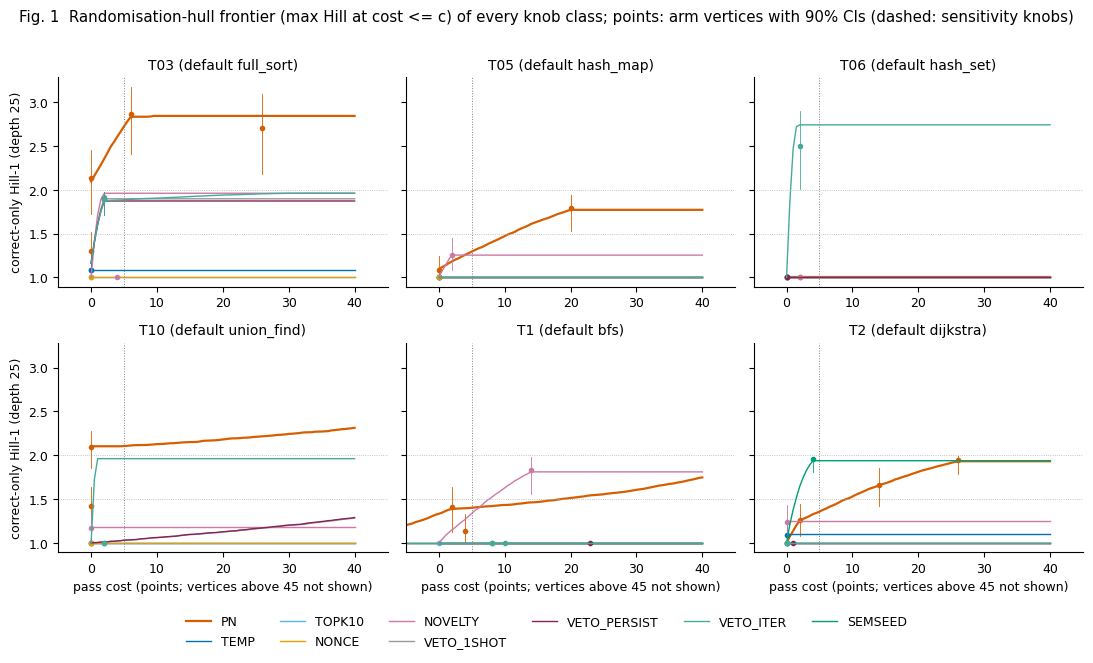

15:07:59|INFO   |figure fig1_hill_vs_cost


(1.0s)


In [22]:
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight"})
OKABE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000", "#999999",
         "#882255", "#44AA99", "#117733"]
CLASS_COL = {"PN": OKABE[3], "TEMP": OKABE[0], "TOPK10": OKABE[5], "NONCE": OKABE[1], "NOVELTY": OKABE[4],
             "SEMSEED": OKABE[2], "VETO_1SHOT": OKABE[8], "VETO_PERSIST": OKABE[9], "VETO_ITER": OKABE[10],
             "MINP": OKABE[7], "VS": OKABE[11]}


def save(fig, name: str) -> None:
    # notebook change: show inline (the original wrote figures/<name>.pdf and .png at dpi 200)
    plt.show()
    plt.close(fig)
    logger.info(f"figure {name}")


def fig1(samples, reused, knob_rows_list) -> None:
    # (was: imports from analysis.core / analysis.hull / analysis.run_all -- defined above; `omap` from section 6)
    U = fixed_uniforms(N_SUB_FIG)
    kr = {(r["task"], r["arm"]): r for r in knob_rows_list}  # was: read_jsonl(RESULTS_DIR / "knob_rows.jsonl")
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharey=True)
    cs = np.linspace(-5, 40, 91)
    for ax, t in zip(axes.ravel(), E6):
        td = TaskData(t, task_rows(samples, reused, t), omap)
        for cls, col in CLASS_COL.items():
            arms = class_vertices(td, cls)
            if arms is None:
                continue
            R = np.array([td.vertex(a)[0] for a in arms])
            P = np.array([td.vertex(a)[1] for a in arms])
            h = Hull(R, P, U)
            ys = [h.best_at_cost(c, refine=False)["hill"] for c in cs]
            ys = [np.nan if y is None else y for y in ys]
            ls = "--" if cls in ("MINP", "VS") else "-"
            ax.plot(cs, ys, color=col, lw=1.6 if cls == "PN" else 1.0, ls=ls, label=cls)
            for a, c in zip(arms[1:], h.cost_v[1:]):
                k = kr.get((t, a))
                if k and k.get("hill25_step0") is not None:
                    lo, hi = k["ci90"] if k["ci90"] and k["ci90"][0] is not None else (None, None)
                    ax.plot([c], [k["hill25_step0"]], "o", color=col, ms=3)
                    if lo is not None:
                        ax.plot([c, c], [lo, hi], color=col, lw=0.6)
        ax.axvline(5, color="0.5", lw=0.7, ls=":")
        for y in (1.5, 2.0):
            ax.axhline(y, color="0.7", lw=0.6, ls=":")
        ax.set_xlim(-5, 45)
        ax.set_title(f"{t} (default {DEFAULT[t]})")
    for ax in axes[1]:
        ax.set_xlabel("pass cost (points; vertices above 45 not shown)")
    axes[0, 0].set_ylabel("correct-only Hill-1 (depth 25)")
    axes[1, 0].set_ylabel("correct-only Hill-1 (depth 25)")
    hl = {}
    for ax in axes.ravel():
        for h_, l_ in zip(*ax.get_legend_handles_labels()):
            hl.setdefault(l_, h_)
    fig.legend(list(hl.values()), list(hl.keys()), loc="lower center", ncol=6, frameon=False,
               bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Fig. 1  Randomisation-hull frontier (max Hill at cost <= c) of every knob class; points: arm "
                 "vertices with 90% CIs (dashed: sensitivity knobs)")
    fig.tight_layout(rect=(0, 0.06, 1, 0.97))
    save(fig, "fig1_hill_vs_cost")


t0 = time.time()
fig1(samples, reused, kr)
print(f"({time.time() - t0:.1f}s)")

**Fig. A (added), the geometry behind H5.** Each curve is one edge of the PN class's hull: the mixtures (1 − λ)·arm_i + λ·arm_j for λ ∈ [0, 1], traced in the (pass cost, Hill) plane. The 5 vertices are TWIN and PN at alpha 0.5, 1, 2 and 4.

- **The star** marks H5, the highest point left of the 5-point line.
- **Mixing can beat both ends.** Mixtures often sit *above* both of their end points. Combining two arms that each favour a different algorithm raises the diversity of the pooled output.

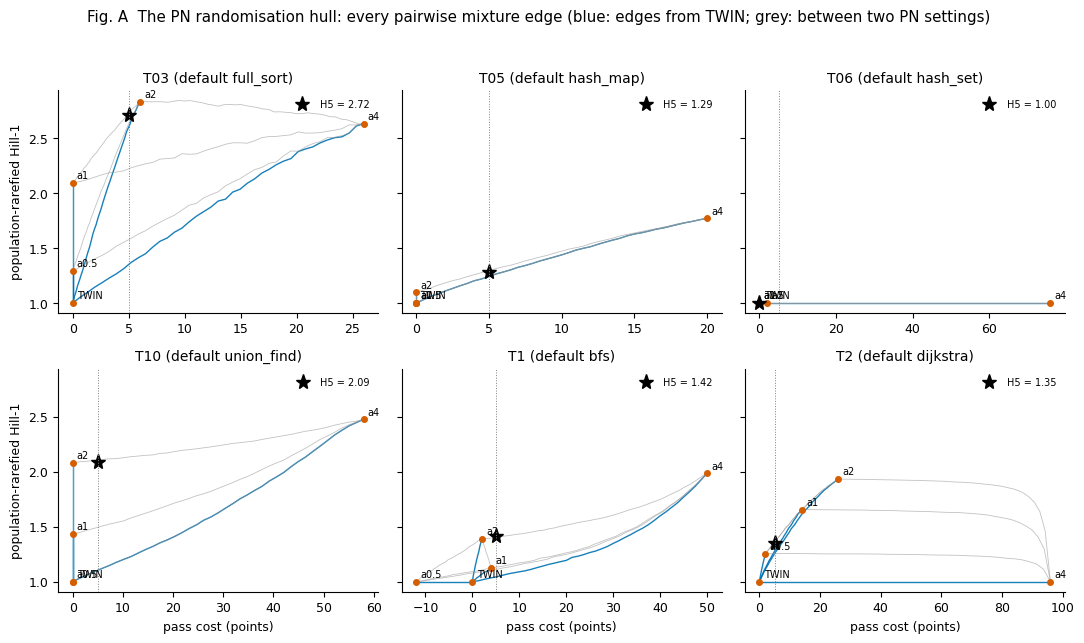

In [23]:
# Added for the notebook: every edge of the PN hull, from the same Hull class the prices use
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharey=True)
U_fig = fixed_uniforms(N_SUB_FIG)
for ax, t in zip(axes.ravel(), E6):
    td = tds[t]
    arms = class_vertices(td, "PN")
    h = Hull(np.array([td.vertex(a)[0] for a in arms]), np.array([td.vertex(a)[1] for a in arms]), U_fig)
    for g in h.grid():
        i, j = g["edge"]
        ax.plot(g["cost"], g["hill"], color=OKABE[0] if i == 0 else OKABE[8], lw=1.0 if i == 0 else 0.6,
                alpha=0.9 if i == 0 else 0.6)
    vh, vc = h.eval_lams(np.eye(len(arms)))
    for a, x, y in zip(arms, vc, vh):
        ax.plot([x], [y], "o", color=OKABE[3], ms=4)
        ax.annotate(a.replace("PN_", ""), (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
    s = point[t]["PN"]
    ax.plot([s["H5_cost"]], [s["H5"]], "*", color="k", ms=11, label=f"H5 = {s['H5']:.2f}")
    ax.axvline(5, color="0.5", lw=0.7, ls=":")
    ax.set_title(f"{t} (default {DEFAULT[t]})")
    ax.legend(frameon=False, fontsize=7, loc="upper right")
for ax in axes[1]:
    ax.set_xlabel("pass cost (points)")
for ax in axes[:, 0]:
    ax.set_ylabel("population-rarefied Hill-1")
fig.suptitle("Fig. A  The PN randomisation hull: every pairwise mixture edge (blue: edges from TWIN; grey: between "
             "two PN settings)")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Fig. 2, what the programs are.** For TWIN, PN at alpha 1 and 2, temperature 1.6 and the novelty instruction, each bar splits the N = 50 programs into three parts: the correct composition coloured by algorithm, then failing (light grey) and invalid (dark grey) programs.

- **Temperature** leaves the composition at the default.
- **PN** moves part of the mass to other algorithms, for example quickselect on T03 and DFS on T10.
- **The novelty instruction** switches T03 wholesale to quickselect.

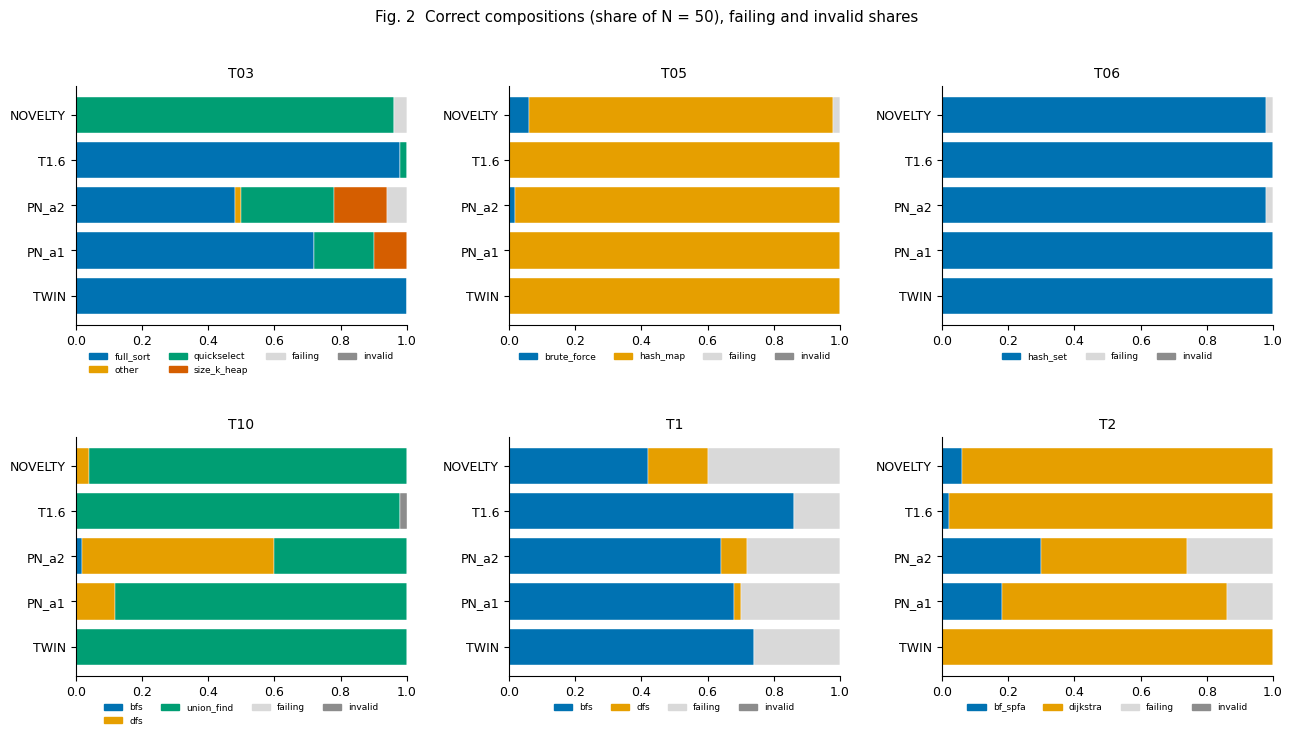

15:08:00|INFO   |figure fig2_compositions


In [24]:
def fig2(T) -> None:
    arms = ["TWIN", "PN_a1", "PN_a2", "T1.6", "NOVELTY"]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
    for ax, t in zip(axes.ravel(), E6):
        labs = sorted({r["label"] for a in arms for r in T[t].get(a, []) if r.get("passed") and r["label"] != "invalid"})
        cols = {l: OKABE[i % len(OKABE)] for i, l in enumerate(labs)}
        for i, a in enumerate(arms):
            rs = T[t].get(a, [])
            if not rs:
                continue
            n = len(rs)
            left = 0.0
            cc = Counter(r["label"] for r in rs if r.get("passed") and r["label"] != "invalid")
            for l in labs:
                w = cc.get(l, 0) / n
                ax.barh(i, w, left=left, color=cols[l], edgecolor="white", lw=0.3,
                        label=l if i == 0 or l not in [x.get_label() for x in ax.patches] else None)
                left += w
            inv = sum(r["label"] == "invalid" for r in rs) / n
            fail = 1 - left - inv
            ax.barh(i, fail, left=left, color="0.85", edgecolor="white", lw=0.3)
            ax.barh(i, inv, left=left + fail, color="0.55", edgecolor="white", lw=0.3)
        ax.set_yticks(range(len(arms)))
        ax.set_yticklabels(arms)
        ax.set_xlim(0, 1)
        ax.set_title(t)
        handles = [plt.Rectangle((0, 0), 1, 1, color=cols[l]) for l in labs] + \
            [plt.Rectangle((0, 0), 1, 1, color="0.85"), plt.Rectangle((0, 0), 1, 1, color="0.55")]
        ax.legend(handles, labs + ["failing", "invalid"], fontsize=6.5, frameon=False, loc="upper center",
                  bbox_to_anchor=(0.5, -0.08), ncol=4)
    fig.suptitle("Fig. 2  Correct compositions (share of N = 50), failing and invalid shares")
    fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=3.0, w_pad=2.0)
    save(fig, "fig2_compositions")


fig2(T)

**Fig. 3, dose-response of plan noise.** The three panels show pass rate, off-default share and correct-only Hill as alpha grows; alpha 0 is TWIN.

- **Off-default share** rises with alpha up to 2 on T03, T10, T1 and T2.
- **T05 and T06** stay pinned to their default until alpha 4.
- **Breakage** (pass below 0.8 × TWIN) comes at alpha 4 on most tasks, alpha 2 on T2 and alpha 8 on T05.

**Fig. B (added), where the push goes inside the model.** Each PN row records the realised displacement ||h_PN − h_twin|| of its prefill: the mean over the task-spec positions S at blocks 12, 23 and 35, and the value at the read position R (the last prompt token, which is never edited) at block 35.

- **Block 12 (first edited block):** the displacement is exactly the target alpha·n. It is linear in alpha, and the relative error along u is ≤ 0.002.
- **Later blocks:** the push grows downstream and reaches the read position through attention.

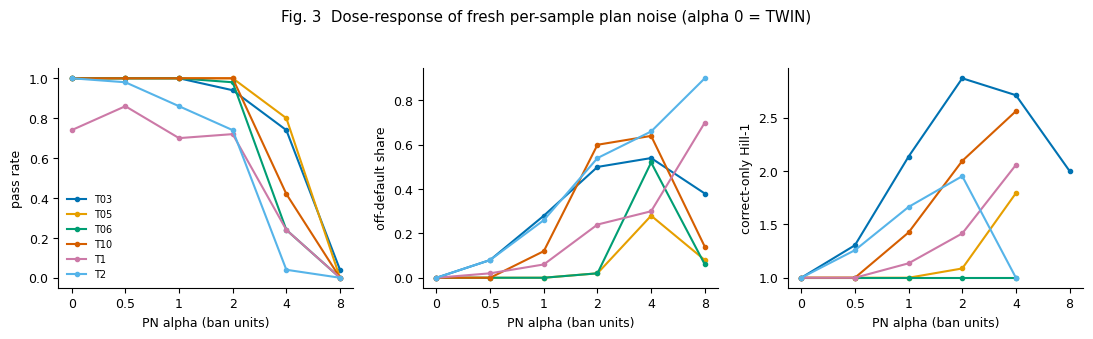

15:08:00|INFO   |figure fig3_alpha_dose_response


max relative error of the displacement along u over all 1500 PN rows: 0.001523


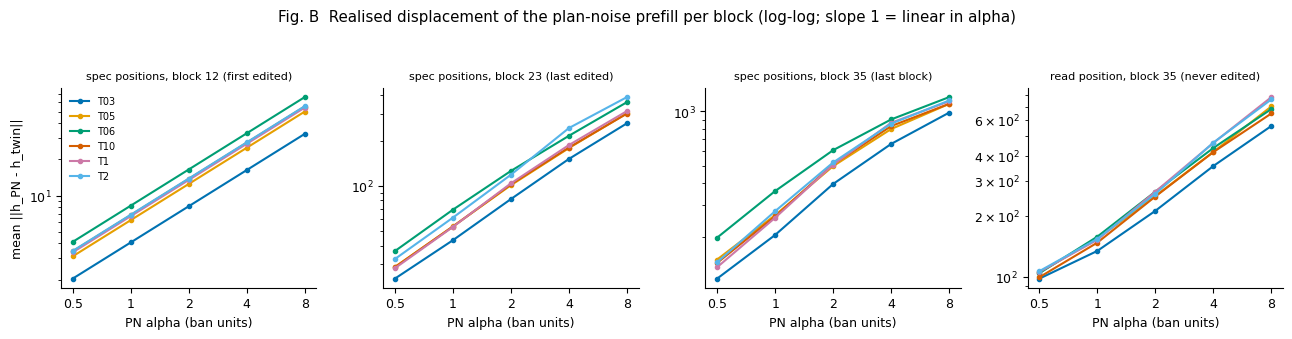

In [25]:
def fig3(sw) -> None:
    # (was: sw = read_json(RESULTS_DIR / "alpha_sweep.json") -- now the in-memory result of alpha_sweep())
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
    for i, t in enumerate(E6):
        if t not in sw:
            continue
        rows = sw[t]["sweep"]
        al = [r["alpha"] for r in rows]
        x = [a if a > 0 else 0.25 for a in al]
        axes[0].plot(x, [r["pass"] for r in rows], "o-", color=OKABE[i], label=t, ms=3)
        axes[1].plot(x, [r["off_default_share"] for r in rows], "o-", color=OKABE[i], ms=3)
        axes[2].plot(x, [r["hill25_step0"] for r in rows], "o-", color=OKABE[i], ms=3)
    for ax, yl in zip(axes, ("pass rate", "off-default share", "correct-only Hill-1")):
        ax.set_xscale("log", base=2)
        ax.set_xticks([0.25, 0.5, 1, 2, 4, 8])
        ax.set_xticklabels(["0", "0.5", "1", "2", "4", "8"])
        ax.set_xlabel("PN alpha (ban units)")
        ax.set_ylabel(yl)
    axes[0].legend(frameon=False, fontsize=7)
    fig.suptitle("Fig. 3  Dose-response of fresh per-sample plan noise (alpha 0 = TWIN)")
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    save(fig, "fig3_alpha_dose_response")


fig3(sw)

# Added for the notebook (Fig. B): realised displacement of every PN prefill, from the per-row summary the run logged
disp = defaultdict(lambda: defaultdict(list))
for r in samples:
    if r.get("realised_disp"):
        disp[r["task"]][ARMS[r["arm"]]["alpha"]].append(r["realised_disp"])
print("max relative error of the displacement along u over all", sum(len(v) for d in disp.values() for v in d.values()),
      "PN rows:", max(x["relerr_u_max"] for d in disp.values() for v in d.values() for x in v))
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharex=True)
for i, t in enumerate(E6):
    al = sorted(disp[t])
    for ax, key in zip(axes, ("S_b12", "S_b23", "S_b35", "R_b35")):
        ax.plot(al, [np.mean([x[key] for x in disp[t][a]]) for a in al], "o-", color=OKABE[i], ms=3, label=t)
for ax, key, title in zip(axes, ("S_b12", "S_b23", "S_b35", "R_b35"),
                          ("spec positions, block 12 (first edited)", "spec positions, block 23 (last edited)",
                           "spec positions, block 35 (last block)", "read position, block 35 (never edited)")):
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks([0.5, 1, 2, 4, 8])
    ax.set_xticklabels(["0.5", "1", "2", "4", "8"])
    ax.set_xlabel("PN alpha (ban units)")
    ax.set_title(title, fontsize=8)
axes[0].set_ylabel("mean ||h_PN - h_twin||")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("Fig. B  Realised displacement of the plan-noise prefill per block (log-log; slope 1 = linear in alpha)")
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

**Fig. 4, ideas vs phrasings (T1).** The x axis is the number of distinct correct *ideas* (Hill-1 of the algorithm labels). The y axis is the number of distinct *phrasings* of the default idea, BFS: clusters among 20 BFS programs at AST-shingle Jaccard ≥ 0.8.

- **Temperature moves up, not right.** It writes the same BFS in more ways: T1.6 has more phrasing clusters than TWIN, and its ideas stay at 1.0.
- **PN and the novelty instruction move right.** They add new algorithms, such as DFS.

This is the CRN-flip result in picture form: at T1.6 the code differs from the TWIN's at 88% of slots, but the algorithm label differs at only 2%. The layout is reduced to the tasks whose code ships (`IDEAS_TASKS`).

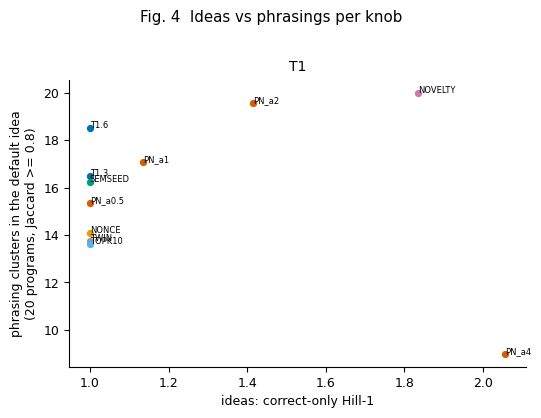

15:08:00|INFO   |figure fig4_ideas_vs_phrasings


In [26]:
def fig4(ip_cells) -> None:
    # (was: ip = read_json(RESULTS_DIR / "ideas_phrasings.json")["cells"] and a 2 x 3 grid over E6; here one panel per
    #  task of IDEAS_TASKS, the tasks whose code ships with the demo data)
    ip = ip_cells
    tasks_ = [t for t in E6 if t in IDEAS_TASKS]
    fig, axes = plt.subplots(1, len(tasks_), figsize=(5.5 * len(tasks_), 4.2), squeeze=False)
    arms_c = {"TWIN": OKABE[8], "PN_a0.5": OKABE[3], "PN_a1": OKABE[3], "PN_a2": OKABE[3], "PN_a4": OKABE[3],
              "T1.3": OKABE[0], "T1.6": OKABE[0], "TOPK10": OKABE[5], "NONCE": OKABE[1], "NOVELTY": OKABE[4],
              "SEMSEED": OKABE[2], "MINP_T1.6": OKABE[7], "MINP_T2.0": OKABE[7], "VS": OKABE[11]}
    for ax, t in zip(axes.ravel(), tasks_):
        for a, col in arms_c.items():
            c = ip.get(f"{t}|{a}")
            if not c or "default_phrasings_theta0.8" not in c:
                continue
            ax.scatter(c["hill_ideas"], c["default_phrasings_theta0.8"], color=col, s=18)
            ax.annotate(a, (c["hill_ideas"], c["default_phrasings_theta0.8"]), fontsize=6)
        ax.set_title(t)
        ax.set_xlabel("ideas: correct-only Hill-1")
        ax.set_ylabel("phrasing clusters in the default idea\n(20 programs, Jaccard >= 0.8)")
    fig.suptitle("Fig. 4  Ideas vs phrasings per knob")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    save(fig, "fig4_ideas_vs_phrasings")


fig4(ip["cells"])

**Fig. 6, the decision.** The plot shows, per task, D_t = H5(PN) − the best comparison knob's H5, with its bootstrap 95% interval. The pooled D̄ sits at the bottom.

- **PN ahead:** T03 and T10.
- **Near zero:** T05 and T1.
- **PN behind:** clearly on T06, where the iterated veto wins, and on T2, where the semantic seed wins.

The pooled D̄ is negative and its interval contains 0, so C1 is PARTIAL.

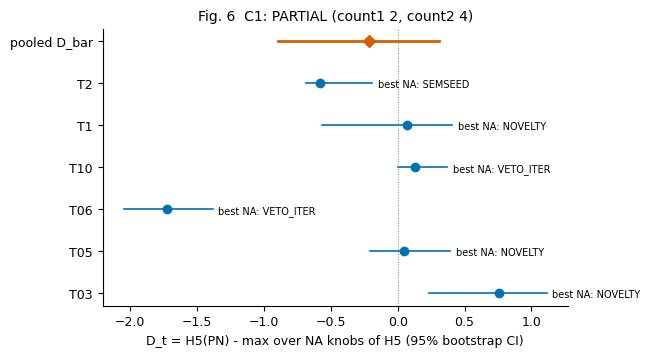

15:08:01|INFO   |figure fig6_forest_Dt


In [27]:
def fig6(c1) -> None:
    # (was: c1 = read_json(RESULTS_DIR / "c1.json")["primary"] -- now the in-memory result of c1_all())
    c1 = c1["primary"]
    per = c1["per_task"]
    ts = [t for t in E6 if t in per and per[t].get("D_t") is not None]
    fig, ax = plt.subplots(figsize=(6, 3.6))
    for i, t in enumerate(ts):
        d = per[t]
        lo, hi = d["D_t_boot_ci95"]
        ax.plot([lo, hi], [i, i], color=OKABE[0], lw=1.2)
        ax.plot([d["D_t"]], [i], "o", color=OKABE[0])
        ax.annotate(f"best NA: {d['best_na']}", (hi, i), fontsize=7, xytext=(4, -3), textcoords="offset points")
    lo, hi = c1["D_bar_ci95"]
    ax.plot([lo, hi], [len(ts), len(ts)], color=OKABE[3], lw=2)
    ax.plot([c1["D_bar"]], [len(ts)], "D", color=OKABE[3])
    ax.axvline(0, color="0.5", lw=0.7, ls=":")
    ax.set_yticks(range(len(ts) + 1))
    ax.set_yticklabels(ts + ["pooled D_bar"])
    ax.set_xlabel("D_t = H5(PN) - max over NA knobs of H5 (95% bootstrap CI)")
    ax.set_title(f"Fig. 6  C1: {c1['verdict']} (count1 {c1['count1']}, count2 {c1['count2']})")
    save(fig, "fig6_forest_Dt")


fig6(c1)

## 14. Summary: the demo run next to the full run

The next cell gathers three things on one screen:

- the headline table, i.e. H5 of PN and of the best comparison knob per task, D_t and the bootstrap probability;
- the "is temperature the creativity knob?" contrast between T1.6 and PN at alpha 2 in CRN flips;
- every class's H5 with its bootstrap interval.

C1 verdict  demo: PARTIAL (count1 2, count2 4, D_bar -0.218 [-0.89, +0.31], 300 replicates)
        full run: PARTIAL (count1 2, count2 4, D_bar -0.218 [-0.89, +0.30], 2000 replicates)

task     default  H5 PN H5 TEMP    best NA H5 best    D_t P(PN>best) full P    T1.6 flips code/label  PN_a2 flips code/label
----------------------------------------------------------------------------------------------------------------------------
T03    full_sort   2.72    1.09    NOVELTY    1.96  +0.76       1.00   1.00              0.14 / 0.02             0.72 / 0.50
T05     hash_map   1.29    1.00    NOVELTY    1.24  +0.05       0.60   0.67              0.32 / 0.00             0.50 / 0.02
T06     hash_set   1.00    1.00  VETO_ITER    2.73  -1.73       0.00   0.00              0.10 / 0.00             0.82 / 0.02
T10   union_find   2.09    1.00  VETO_ITER    1.96  +0.13       0.92   0.91              0.48 / 0.02             0.90 / 0.60
T1           bfs   1.42    1.00    NOVELTY    1.34  +0.07       

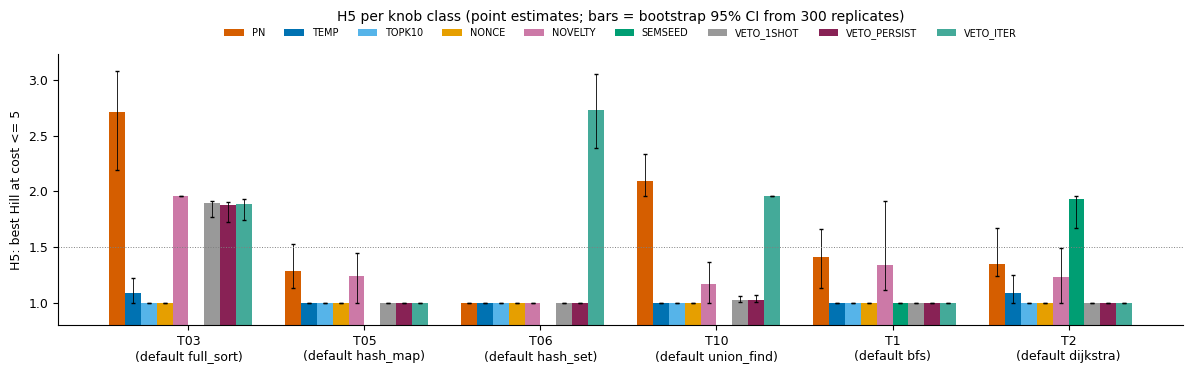

In [28]:
# Added for the notebook: one-screen summary of this run (demo scale) next to the full run's numbers
pr, ref_c1 = c1["primary"], meta["reference"]["c1_primary"]
print(f"C1 verdict  demo: {pr['verdict']} (count1 {pr['count1']}, count2 {pr['count2']}, D_bar {pr['D_bar']:+.3f} "
      f"[{pr['D_bar_ci95'][0]:+.2f}, {pr['D_bar_ci95'][1]:+.2f}], {N_BOOT} replicates)")
print(f"        full run: {ref_c1['verdict']} (count1 {ref_c1['count1']}, count2 {ref_c1['count2']}, D_bar "
      f"{ref_c1['D_bar']:+.3f} [{ref_c1['D_bar_ci95'][0]:+.2f}, {ref_c1['D_bar_ci95'][1]:+.2f}], 2000 replicates)\n")
hdr = (f"{'task':<5}{'default':>11}{'H5 PN':>7}{'H5 TEMP':>8}{'best NA':>11}{'H5 best':>8}{'D_t':>7}{'P(PN>best)':>11}"
       f"{'full P':>7}   {'T1.6 flips code/label':>22}{'PN_a2 flips code/label':>24}")
print(hdr)
print("-" * len(hdr))
for t in E6:
    d, q = pr["per_task"][t], ref_c1["per_task"][t]
    f16, f2 = fl[f"{t}|T1.6"], fl[f"{t}|PN_a2"]
    print(f"{t:<5}{DEFAULT[t]:>11}{d['H5_PN']:>7.2f}{point[t]['TEMP']['H5']:>8.2f}{d['best_na']:>11}"
          f"{d['H5_best']:>8.2f}{d['D_t']:>+7.2f}{d['P_boot_PN_gt_best']:>11.2f}{q['P_boot_PN_gt_best']:>7.2f}   "
          f"{f16['P_code_differs']:>15.2f} / {f16['P_label_differs']:.2f}"
          f"{f2['P_code_differs']:>17.2f} / {f2['P_label_differs']:.2f}")

# H5 of every comparison class with its bootstrap 95% interval
cls_plot = ["PN", "TEMP", "TOPK10", "NONCE", "NOVELTY", "SEMSEED", "VETO_1SHOT", "VETO_PERSIST", "VETO_ITER"]
fig, ax = plt.subplots(figsize=(12, 3.8))
wdt = 0.09
for j, c in enumerate(cls_plot):
    xs, ys, lo_, hi_ = [], [], [], []
    for i, t in enumerate(E6):
        if c in point[t] and point[t][c]["H5"] is not None:
            ci = c1["class_ci"][t].get(c, {}).get("H5_ci95", [None, None])
            v = point[t][c]["H5"]
            xs.append(i + (j - len(cls_plot) / 2) * wdt)
            ys.append(v)
            lo_.append(v - ci[0] if ci[0] is not None else 0.0)
            hi_.append(ci[1] - v if ci[1] is not None else 0.0)
    ax.bar(xs, ys, width=wdt, color=CLASS_COL[c], label=c, yerr=[np.clip(lo_, 0, None), np.clip(hi_, 0, None)],
           error_kw={"lw": 0.6, "capsize": 1.5})
ax.axhline(1.5, color="0.5", lw=0.7, ls=":")
ax.set_xticks(range(len(E6)))
ax.set_xticklabels([f"{t}\n(default {DEFAULT[t]})" for t in E6])
ax.set_ylabel("H5: best Hill at cost <= 5")
ax.set_ylim(0.8, None)
ax.legend(ncol=9, fontsize=7, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.13))
ax.set_title(f"H5 per knob class (point estimates; bars = bootstrap 95% CI from {N_BOOT} replicates)", pad=24)
fig.tight_layout()
plt.show()

## Takeaways

- **Temperature is not a creativity knob for algorithms.** T1.3, T1.6 and top-k 10 leave H5 at ≈ 1 on every decisive task.
  - Temperature changes the *code*: at T1.6 the program differs from the twin's in most CRN slots.
  - It almost never changes the *algorithm*. On the grid path-search task T1 it writes BFS again, in more phrasings.
  - Top-k 10 never changed a single program, because the model's top-10 mass is essentially 1 on these prompts.
- **Plan noise changes the algorithm.** A fresh random push of about one ban unit at the task-spec positions of blocks 12–23 flips the algorithm label in about half of the CRN slots at alpha 2 on T03, T10 and T2.
  - Where it works (T03, T10), it is the cheapest knob: Hill 1.5 and even Hill 2 are reached at **zero** pass cost.
  - Above alpha ≈ 2–4 the programs break.
- **It is not uniformly cheapest, so C1 is PARTIAL.** Targeted content beats random noise where it names the alternative:
  - On T06 (find duplicate) PN cannot move `hash_set` at all, while the iterated veto ("not that one, nor that one") reaches 2.73.
  - On T2 (weighted shortest path), the semantic seed wins. It tells a story of relaxation rounds ("news spreads through a kingdom in rounds …"), and 20 of 50 programs switch from Dijkstra to Bellman–Ford / SPFA with almost no failures.
  - PN reaches the same alternative on T2 only at a pass cost of 14–26 points.
- **Point estimates are exact and the verdict is robust.** Every point estimate above is recomputed from the labelled programs with the original code and matches the full run exactly. Only the bootstrap intervals are Monte-Carlo approximations at demo scale. The verdict is PARTIAL with any replicate count.

**Scaling up.** Raise `N_BOOT` to 2000 and `N_BOOT_SENS` to 1000 in the config cell to reproduce the full run's intervals. This takes about 0.25 s per primary replicate and about 1.1 s per sensitivity replicate on one CPU core. The GPU stage needs the artifact's `method.py gpu` on an FP8-capable ≥ 16 GB GPU with the Qwen3-8B weights.